# ACE Latent Class Analysis
二元 Bernoulli 潜在类别模型，比较 1–6 类，采用五类进行后续分析。所有实现均内置；SCD 不参与类别拟合。

In [1]:
from pathlib import Path
from IPython.display import display, Image, Markdown
cwd = Path.cwd().resolve()
if (cwd.parent / 'Preprocessing' / 'BRFSS_2023_ACE_SCD_main.csv').exists():
    ROOT = cwd
elif (cwd / 'Preprocessing' / 'BRFSS_2023_ACE_SCD_main.csv').exists():
    ROOT = cwd / 'ACE_classification_gao'
else:
    raise FileNotFoundError('请从项目根目录或 ACE_classification_gao 目录启动，确保 Preprocessing 中的 CSV 存在。')
ROOT.mkdir(exist_ok=True)


### ACE 字段定义、数据校验及描述性分析函数

In [3]:
"""Reproducible Section C analysis; all artifacts stay beside this script."""
from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
SOURCE = ROOT.parent / 'Preprocessing' / 'BRFSS_2023_ACE_SCD_main.csv'
GROUPS = ['0', '1', '2-3', '4+']
LABELS = {'ACEDEPRS_bin': 'Household mental illness', 'ACEDRINK_bin': 'Household alcohol problems', 'ACEDRUGS_bin': 'Household drug misuse', 'ACEPRISN_bin': 'Household incarceration', 'ACEDIVRC_bin': 'Parental separation/divorce', 'ACEPUNCH_bin': 'Violence between parents', 'ACEHURT1_bin': 'Physical abuse', 'ACESWEAR_bin': 'Verbal abuse', 'ACETOUCH_bin': 'Sexual touching', 'ACETTHEM_bin': 'Made to touch sexually', 'ACEHVSEX_bin': 'Forced sex'}
COLS = list(LABELS)
DEMOGRAPHICS = {'sex': ['Male', 'Female', 'Missing'], 'education': ['High school or less', 'Attended college', 'College graduate', 'Missing'], 'income': ['<$15k', '$15-25k', '$25-35k', '$35-50k', '$50-100k', '$100-200k', '>=$200k', 'Missing'], 'age_group': ['45-54', '55-64', '65-74', '75+', 'Missing'], 'marital': ['Married or living with partner', 'Previously married', 'Never married', 'Missing'], 'race': ['White, non-Hispanic', 'Black, non-Hispanic', 'Hispanic', 'Others, non-Hispanic', 'Missing']}

def save_table(frame, name, index=False):
    frame.to_csv(ROOT / 'tables' / (name + '.csv'), index=index, encoding='utf-8-sig')

def save_figure(fig, name):
    fig.savefig(ROOT / 'figures' / (name + '.png'), dpi=300, bbox_inches='tight')
    fig.savefig(ROOT / 'figures' / (name + '.pdf'), bbox_inches='tight')
    plt.close(fig)

def load_data():
    d = pd.read_csv(SOURCE)
    if not d[COLS].isin([0, 1]).all().all():
        raise ValueError('ACE items must be complete binary values; missing is never scored as zero.')
    if not (np.isfinite(d['_LLCPWT']) & d['_LLCPWT'].gt(0)).all():
        raise ValueError('Survey weights must be finite and positive.')
    d['ACE_score_recalculated'] = d[COLS].sum(axis=1, min_count=11).astype(int)
    if not d['ACE_score_recalculated'].eq(d['ACE_score_11']).all():
        raise ValueError('Recalculated scores differ from preprocessing.')
    if not d['_AGE80'].between(45, 80).all():
        raise ValueError('Unexpected age outside the analytic sample.')
    for i, col in enumerate(COLS):
        mapping = {1: 1, 2: 0} if i < 5 else {1: 0, 2: 1, 3: 1}
        if not d[col.removesuffix('_bin')].map(mapping).eq(d[col]).all():
            raise ValueError(f'Raw/binary mismatch: {col}')
    d['ace_group'] = pd.cut(d['ACE_score_recalculated'], [-1, 0, 1, 3, 11], labels=GROUPS)
    d['source_row'] = np.arange(2, len(d) + 2)
    d['sex'] = d['SEXVAR'].map({1: 'Male', 2: 'Female'}).fillna('Missing')
    d['education'] = d['EDUCA'].map({1: 'High school or less', 2: 'High school or less', 3: 'High school or less', 4: 'High school or less', 5: 'Attended college', 6: 'College graduate'}).fillna('Missing')
    d['income'] = d['INCOME3'].map({1: '<$15k', 2: '<$15k', 3: '$15-25k', 4: '$15-25k', 5: '$25-35k', 6: '$35-50k', 7: '$50-100k', 8: '$50-100k', 9: '$100-200k', 10: '$100-200k', 11: '>=$200k'}).fillna('Missing')
    d['age_group'] = pd.cut(d['_AGE80'], [44, 54, 64, 74, 80], labels=DEMOGRAPHICS['age_group'][:-1]).astype('object').fillna('Missing')
    d['marital'] = d['MARITAL'].map({1: 'Married or living with partner', 6: 'Married or living with partner', 2: 'Previously married', 3: 'Previously married', 4: 'Previously married', 5: 'Never married'}).fillna('Missing')
    d['race'] = d['_RACEGR3'].map({1: 'White, non-Hispanic', 2: 'Black, non-Hispanic', 3: 'Others, non-Hispanic', 4: 'Others, non-Hispanic', 5: 'Hispanic'}).fillna('Missing')
    return d

def distribution(d, column, order):
    g = d.groupby(column, observed=True).agg(n=(column, 'size'), weight_sum=('_LLCPWT', 'sum')).reindex(order, fill_value=0)
    g['unweighted_pct'] = 100 * g['n'] / len(d)
    g['weighted_pct'] = 100 * g['weight_sum'] / d['_LLCPWT'].sum()
    return g.rename_axis(column).reset_index()

def run_analysis():
    for folder in ['tables', 'figures', 'data']:
        (ROOT / folder).mkdir(exist_ok=True)
    plt.rcParams.update({'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})
    d = load_data()
    d.to_csv(ROOT / 'data' / 'BRFSS_2023_ACE_classified.csv', index=False, encoding='utf-8-sig')
    groups = distribution(d, 'ace_group', GROUPS)
    scores = distribution(d, 'ACE_score_recalculated', range(12))
    save_table(groups, 'ace_group_distribution')
    save_table(scores, 'ace_score_distribution')
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
    for ax, metric, title in zip(axes, ['n', 'weighted_pct'], ['Observed sample counts', 'Survey-weighted distribution']):
        bars = ax.bar(GROUPS, groups[metric], color=['#477D60', '#4E79A7', '#E6A23C', '#BD5252'])
        ax.bar_label(bars, labels=[f'{v:,.0f}' if metric == 'n' else f'{v:.1f}%' for v in groups[metric]], padding=4)
        ax.set(xlabel='ACE item score group', ylabel='Respondents' if metric == 'n' else 'Weighted %', title=title, ylim=(0, groups[metric].max() * 1.17))
    fig.tight_layout()
    save_figure(fig, 'Fig1_ACE_group_distribution')
    x = d[COLS].to_numpy(dtype=float)
    w = d['_LLCPWT'].to_numpy(dtype=float)
    counts = x.T @ x
    joint = 100 * (x.T @ (x * w[:, None])) / w.sum()
    means = np.average(x, axis=0, weights=w)
    cov = x.T @ (x * w[:, None]) / w.sum() - np.outer(means, means)
    phi = cov / np.sqrt(np.outer(means * (1 - means), means * (1 - means)))
    for matrix, name in [(counts, 'cooccurrence_unweighted_n'), (joint, 'cooccurrence_weighted_pct'), (phi, 'weighted_phi_correlation')]:
        save_table(pd.DataFrame(matrix, index=COLS, columns=COLS), name, index=True)
    fig, ax = plt.subplots(figsize=(12, 10))
    im = ax.imshow(joint, cmap='YlOrRd', vmin=0)
    ax.set_xticks(range(11), LABELS.values(), rotation=55, ha='right')
    ax.set_yticks(range(11), LABELS.values())
    for i in range(11):
        for j in range(11):
            ax.text(j, i, f'{joint[i, j]:.1f}', ha='center', va='center', color='white' if joint[i, j] > joint.max() * 0.6 else 'black', fontsize=8)
    fig.colorbar(im, ax=ax, label='Both items present: weighted % of all respondents')
    ax.set_title('ACE pairwise co-occurrence\nDiagonal = individual item prevalence; pairs may include other ACEs')
    save_figure(fig, 'Fig2_ACE_cooccurrence_heatmap')
    pairs = pd.DataFrame([{'item_1': COLS[i], 'item_2': COLS[j], 'n_both': int(counts[i, j]), 'weighted_joint_pct': joint[i, j], 'weighted_phi': phi[i, j]} for i in range(11) for j in range(i + 1, 11)]).sort_values('weighted_joint_pct', ascending=False)
    save_table(pairs, 'ace_pair_rankings')
    patterns = d.groupby(COLS, observed=True).agg(n=('SCD', 'size'), weight_sum=('_LLCPWT', 'sum')).reset_index().sort_values(['n'] + COLS, ascending=[False] + [True] * 11).reset_index(drop=True)
    patterns['pattern'] = patterns[COLS].astype(int).astype(str).agg(''.join, axis=1)
    patterns['n_ace_items'] = patterns[COLS].sum(axis=1).astype(int)
    patterns['unweighted_pct'] = 100 * patterns['n'] / len(d)
    patterns['weighted_pct'] = 100 * patterns['weight_sum'] / w.sum()
    patterns['description'] = patterns[COLS].apply(lambda r: ' + '.join((LABELS[c] for c in COLS if r[c])) or 'No ACEs', axis=1)
    save_table(patterns, 'ace_exact_patterns_all')
    top = patterns.loc[patterns['n_ace_items'] > 0].head(20).reset_index(drop=True)
    save_table(top, 'ace_exact_patterns_top20_exposed')
    fig = plt.figure(figsize=(17, 9))
    grid = fig.add_gridspec(2, 2, width_ratios=[4, 10], height_ratios=[4, 5], hspace=0.08, wspace=0.08)
    bars_ax = fig.add_subplot(grid[0, 1])
    matrix_ax = fig.add_subplot(grid[1, 1], sharex=bars_ax)
    sets_ax = fig.add_subplot(grid[1, 0], sharey=matrix_ax)
    bars = bars_ax.bar(range(len(top)), top['n'], color='#37788A')
    bars_ax.bar_label(bars, labels=[f'{n:,}' for n in top['n']], fontsize=8, rotation=45, padding=3)
    bars_ax.set(ylabel='Exact intersection size (unweighted n)', ylim=(0, top['n'].max() * 1.3))
    bars_ax.tick_params(axis='x', bottom=False, labelbottom=False)
    for j, row in top.iterrows():
        active = np.flatnonzero(row[COLS].to_numpy(dtype=int))
        matrix_ax.scatter([j] * 11, range(11), color='#DDDDDD', s=25)
        matrix_ax.plot([j] * len(active), active, color='#244F60', linewidth=2)
        matrix_ax.scatter([j] * len(active), active, color='#244F60', s=40)
    matrix_ax.set(ylim=(10.6, -0.6), xlabel='Top 20 nonempty exact ACE combinations, ranked by sample count', xticks=[])
    matrix_ax.tick_params(axis='y', left=False, labelleft=False)
    sets_ax.barh(range(11), x.sum(axis=0), color='#BAA14D')
    sets_ax.set_yticks(range(11), LABELS.values(), fontsize=9)
    sets_ax.invert_xaxis()
    sets_ax.set_xlabel('All-sample item counts')
    zero = patterns.loc[patterns['n_ace_items'].eq(0)].iloc[0]
    coverage = top['n'].sum() / len(d) * 100
    fig.suptitle(f"ACE exact combinations (UpSet plot)\nNo ACEs: n={zero['n']:,}; displayed combinations cover {coverage:.1f}% of the full sample", y=0.98)
    save_figure(fig, 'Fig3_ACE_UpSet_top20')
    demographic_rows = []
    for variable, levels in DEMOGRAPHICS.items():
        for group in GROUPS:
            sub = d.loc[d['ace_group'].eq(group)]
            for level in levels:
                mask = sub[variable].eq(level)
                demographic_rows.append({'variable': variable, 'level': level, 'ace_group': group, 'n': int(mask.sum()), 'group_n': len(sub), 'unweighted_pct': 100 * mask.mean(), 'weighted_pct': 100 * sub.loc[mask, '_LLCPWT'].sum() / sub['_LLCPWT'].sum()})
    demographics = pd.DataFrame(demographic_rows)
    save_table(demographics, 'demographics_by_ace_group_long')
    wide = demographics.assign(cell=demographics.apply(lambda r: f"{r['n']:,} ({r['weighted_pct']:.1f}%)", axis=1)).pivot(index=['variable', 'level'], columns='ace_group', values='cell').reindex(columns=GROUPS)
    save_table(wide, 'demographics_by_ace_group_n_weighted_pct', index=True)
    for number, variables in [(4, ['sex', 'education', 'income']), (5, ['age_group', 'marital', 'race'])]:
        fig, axes = plt.subplots(1, 3, figsize=(17, 6.5))
        for ax, variable in zip(axes, variables):
            block = demographics.loc[demographics['variable'].eq(variable)]
            bottom = np.zeros(4)
            levels = DEMOGRAPHICS[variable]
            colors = plt.get_cmap('tab20')(np.linspace(0, 0.9, len(levels)))
            for level, color in zip(levels, colors):
                values = block.loc[block['level'].eq(level)].set_index('ace_group').reindex(GROUPS)['weighted_pct'].to_numpy()
                ax.bar(GROUPS, values, bottom=bottom, label=level, color='#BBBBBB' if level == 'Missing' else color, width=0.7)
                for i, v in enumerate(values):
                    if v >= 7:
                        ax.text(i, bottom[i] + v / 2, f'{v:.1f}', ha='center', va='center', fontsize=8)
                bottom += values
            ax.set(title=variable.replace('_', ' ').title(), xlabel='ACE item score group', ylabel='Weighted within-group %', ylim=(0, 100))
            ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.13), frameon=False, fontsize=8)
        fig.suptitle('Demographic composition within ACE groups (missing retained)')
        fig.subplots_adjust(bottom=0.34, wspace=0.3, top=0.88)
        save_figure(fig, f'Fig{number}_demographics_' + '_'.join(variables))
    assert groups['n'].sum() == len(d) == patterns['n'].sum()
    assert np.isclose(groups['weighted_pct'].sum(), 100)
    assert np.allclose(demographics.groupby(['variable', 'ace_group'])['weighted_pct'].sum(), 100)
    assert np.allclose(joint, joint.T) and np.allclose(np.diag(joint), means * 100)
    assert np.allclose(np.diag(phi), 1)
    audit = {'source': str(SOURCE.relative_to(ROOT.parent)), 'source_sha256': hashlib.sha256(SOURCE.read_bytes()).hexdigest(), 'n': len(d), 'states': sorted(d['_STATE'].unique().astype(int).tolist()), 'ace_score_mismatches': int(d['ACE_score_recalculated'].ne(d['ACE_score_11']).sum()), 'raw_binary_mismatches': 0, 'ace_missing_cells': int(d[COLS].isna().sum().sum()), 'exact_patterns': len(patterns), 'top20_full_sample_coverage_pct': coverage, 'validation': 'passed', 'versions': {'pandas': pd.__version__, 'numpy': np.__version__}}
    (ROOT / 'tables' / 'validation.json').write_text(json.dumps(audit, ensure_ascii=False, indent=2), encoding='utf-8')
    return {'data': d, 'groups': groups, 'scores': scores, 'pairs': pairs, 'patterns': patterns, 'demographics': demographics, 'audit': audit}


### 二元 LCA 拟合、五类选择与可视化函数

In [4]:
"""Binary latent class models fitted by EM to exact response-pattern counts.

Primary analysis: unweighted maximum likelihood, K=1..6, repeated random starts.
Survey weights are used for descriptive summaries after fitting, not for ML/BIC.
"""
from pathlib import Path
import argparse
import json
import hashlib
import numpy as np
import pandas as pd
from scipy.special import logsumexp
import matplotlib.pyplot as plt
OUT = ROOT / 'lca'
EPS = 1e-09

def posterior(x, pi, theta):
    logp = np.log(pi)[None, :] + x @ np.log(theta).T + (1 - x) @ np.log1p(-theta).T
    norm = logsumexp(logp, axis=1)
    return (np.exp(logp - norm[:, None]), norm)

def fit_em(x, counts, k, seed, max_iter=10000, tol=1e-05):
    rng = np.random.default_rng(seed)
    pi = np.ones(k) / k
    theta = rng.uniform(0.05, 0.8, (k, x.shape[1]))
    history = []
    converged = False
    for iteration in range(max_iter + 1):
        r, norm = posterior(x, pi, theta)
        ll = float(counts @ norm)
        history.append(ll)
        if len(history) > 1:
            gain = history[-1] - history[-2]
            if gain < -1e-06:
                raise ArithmeticError('EM likelihood decreased')
            if abs(gain) < tol:
                converged = True
                break
        if iteration == max_iter:
            break
        mass = r * counts[:, None]
        nk = mass.sum(axis=0)
        pi = np.maximum(nk, EPS)
        pi /= pi.sum()
        theta = np.clip(mass.T @ x / nk[:, None], EPS, 1 - EPS)
    order = np.argsort(theta.sum(axis=1), kind='stable')
    return {'pi': pi[order], 'theta': theta[order], 'll': ll, 'converged': converged, 'iterations': iteration, 'seed': seed, 'history': history}

def fit_starts(x, counts, k, starts, base_seed):
    fits = [fit_em(x, counts, k, base_seed + k * 1000 + s) for s in range(starts)]
    valid = [m for m in fits if m['converged']]
    if not valid:
        raise RuntimeError(f'K={k}: no converged starts; increase max_iter')
    best = max(valid, key=lambda m: m['ll'])
    rows = [{'k': k, 'start': s + 1, 'seed': m['seed'], 'log_likelihood': m['ll'], 'converged': m['converged'], 'iterations': m['iterations'], 'best_replicated': bool(m['converged'] and abs(m['ll'] - best['ll']) < 0.01)} for s, m in enumerate(fits)]
    return (best, rows)

def table(d, name, index=False):
    d.to_csv(OUT / 'tables' / f'{name}.csv', index=index, encoding='utf-8-sig')

def figure(fig, name):
    for ext in ['png', 'pdf']:
        fig.savefig(OUT / 'figures' / f'{name}.{ext}', dpi=300, bbox_inches='tight')
    plt.close(fig)

def profile_name(theta):
    """Descriptive names from fitted probabilities; thresholds are interpretive only."""
    burden = theta.sum()
    sexual = theta[8:].mean()
    if burden < 1:
        return '较低 ACE 暴露型'
    if sexual > 0.5:
        return '多重 ACE 伴较高性虐待暴露型' if burden > 5 else '性虐待条目突出型'
    if burden > 4:
        return '多重家庭问题及虐待暴露型'
    if theta[6] > 0.5 and theta[7] > 0.5:
        return '身体及言语虐待突出型'
    return LABELS[COLS[int(np.argmax(theta))]] + ' 突出型'

def run_lca(starts=30, seed=20261102, selected_k=5):
    for sub in ['tables', 'figures', 'models', 'data']:
        (OUT / sub).mkdir(parents=True, exist_ok=True)
    d = load_data()
    raw = d[COLS].to_numpy(float)
    x, inverse, counts = np.unique(raw, axis=0, return_inverse=True, return_counts=True)
    n = len(d)
    models, comparisons, diagnostics = ({}, [], [])
    for k in range(1, 7):
        m, runs = fit_starts(x, counts.astype(float), k, 1 if k == 1 else starts, seed)
        models[k] = m
        diagnostics.extend(runs)
        r, _ = posterior(x, m['pi'], m['theta'])
        hard = np.bincount(r.argmax(axis=1), weights=counts, minlength=k)
        entropy = np.nan if k == 1 else 1 + float(np.sum(counts[:, None] * r * np.log(np.maximum(r, EPS)))) / (n * np.log(k))
        params = k * len(COLS) + (k - 1)
        comparisons.append({'k': k, 'parameters': params, 'log_likelihood': m['ll'], 'AIC': -2 * m['ll'] + 2 * params, 'BIC': -2 * m['ll'] + params * np.log(n), 'entropy': entropy, 'min_model_class_pct': 100 * m['pi'].min(), 'min_modal_class_n': int(hard.min()), 'min_modal_class_pct': 100 * hard.min() / n, 'converged_starts': sum((z['converged'] for z in runs)), 'best_replications': sum((z['best_replicated'] for z in runs)), 'boundary_probabilities': int(((m['theta'] < 0.001) | (m['theta'] > 0.999)).sum())})
        np.savez_compressed(OUT / 'models' / f'lca_k{k}.npz', pi=m['pi'], theta=m['theta'], columns=np.array(COLS), seed=m['seed'], log_likelihood=m['ll'], history=m['history'])
        print(f"K={k}: LL={m['ll']:.3f}; repeated optimum={comparisons[-1]['best_replications']}", flush=True)
    comparison = pd.DataFrame(comparisons)
    bic_best_k = int(comparison.loc[comparison['BIC'].idxmin(), 'k'])
    k = selected_k
    if k not in models:
        raise ValueError('selected_k must be between 1 and 6')
    comparison['delta_BIC'] = comparison['BIC'] - comparison['BIC'].min()
    comparison['bic_best'] = comparison['k'].eq(bic_best_k)
    comparison['selected_candidate'] = comparison['k'].eq(k)
    table(comparison, 'model_comparison')
    table(pd.DataFrame(diagnostics), 'random_start_diagnostics')
    m = models[k]
    names = ['低 ACE 暴露型', '身体与言语虐待型', '性虐待主导型', '家庭功能障碍型', '多重 ACE 暴露型'] if k == 5 else [profile_name(theta) for theta in m['theta']]
    rp, _ = posterior(x, m['pi'], m['theta'])
    r = rp[inverse]
    modal = r.argmax(axis=1)
    assert np.allclose(r.sum(axis=1), 1)
    assigned = d.copy()
    assigned['lca_class'] = modal + 1
    assigned['lca_max_posterior'] = r.max(axis=1)
    assigned['lca_uncertain_lt_0_70'] = r.max(axis=1) < 0.7
    for c in range(k):
        assigned[f'lca_p_class_{c + 1}'] = r[:, c]
    assigned['lca_profile_label'] = [names[c] for c in modal]
    assigned.to_csv(OUT / 'data' / 'BRFSS_2023_ACE_LCA_classified.csv', index=False, encoding='utf-8-sig')
    probs = pd.DataFrame(m['theta'].T, index=COLS, columns=[f'Class {i + 1}' for i in range(k)])
    table(probs, 'selected_item_probabilities', index=True)
    rows = []
    for c in range(k):
        mask = modal == c
        sub = d.loc[mask]
        top = np.argsort(-m['theta'][c])[:3]
        rows.append({'class': c + 1, 'profile_label': names[c], 'model_proportion_pct': m['pi'][c] * 100, 'modal_n': int(mask.sum()), 'modal_unweighted_pct': mask.mean() * 100, 'modal_weighted_pct': sub['_LLCPWT'].sum() / d['_LLCPWT'].sum() * 100, 'expected_ace_items': m['theta'][c].sum(), 'mean_assigned_posterior': float(r[mask, c].mean()) if mask.any() else np.nan, 'uncertain_lt_0_70_pct': float((r[mask, c] < 0.7).mean() * 100) if mask.any() else np.nan, 'leading_items': '; '.join((f"{LABELS[COLS[j]]}: {m['theta'][c, j]:.2f}" for j in top)), 'SCD_n': int(sub['SCD'].sum()), 'SCD_unweighted_pct': sub['SCD'].mean() * 100, 'SCD_weighted_pct': np.average(sub['SCD'], weights=sub['_LLCPWT']) * 100 if len(sub) else np.nan})
    summary = pd.DataFrame(rows)
    table(summary, 'selected_class_summary')
    quality = pd.DataFrame([r[modal == c].mean(axis=0) for c in range(k)], index=pd.Index(range(1, k + 1), name='assigned_class'), columns=[f'posterior_class_{c + 1}' for c in range(k)])
    table(quality, 'classification_posterior_matrix', index=True)
    cross = pd.crosstab(assigned['lca_class'], assigned['ace_group']).reindex(columns=['0', '1', '2-3', '4+'], fill_value=0)
    table(cross, 'class_vs_ace_score_group_n', index=True)
    table(cross.div(cross.sum(axis=1), axis=0) * 100, 'class_vs_ace_score_group_row_pct', index=True)
    observed = raw.T @ raw / n
    expected = np.einsum('c,ci,cj->ij', m['pi'], m['theta'], m['theta'])
    residuals = pd.DataFrame([{'item_1': COLS[i], 'item_2': COLS[j], 'observed_joint_pct': observed[i, j] * 100, 'model_joint_pct': expected[i, j] * 100, 'residual_percentage_points': (observed[i, j] - expected[i, j]) * 100} for i in range(11) for j in range(i + 1, 11)])
    residuals['absolute_residual_pp'] = residuals['residual_percentage_points'].abs()
    table(residuals.sort_values('absolute_residual_pp', ascending=False), 'pairwise_model_residuals')
    soft = []
    w = d['_LLCPWT'].to_numpy()
    y = d['SCD'].to_numpy()
    for c in range(k):
        soft.append({'class': c + 1, 'posterior_weighted_SCD_pct': 100 * np.average(y, weights=r[:, c]), 'survey_and_posterior_weighted_SCD_pct': 100 * np.average(y, weights=w * r[:, c])})
    table(pd.DataFrame(soft), 'SCD_posterior_weighting_descriptive_sensitivity')
    draw_figures(comparison, probs, summary)
    selected = comparison.loc[comparison['k'].eq(k)].iloc[0]
    audit = {'n': n, 'response_patterns': len(x), 'source_sha256': hashlib.sha256(SOURCE.read_bytes()).hexdigest(), 'seed': seed, 'starts_per_k': starts, 'selected_k': k, 'bic_best_k': bic_best_k, 'selection': 'researcher-selected K=5 balancing fit, entropy, parsimony and profile interpretability; not the BIC minimum' if k == 5 else 'researcher-selected class count', 'selected_delta_BIC': float(selected['delta_BIC']), 'selected_best_replications': int(selected['best_replications']), 'entropy': float(selected['entropy']), 'uncertain_lt_0_70_pct': float((r.max(axis=1) < 0.7).mean() * 100), 'primary_fit': 'unweighted ML; no survey design adjustment', 'max_iter': 10000, 'absolute_ll_tolerance': 1e-05, 'versions': {'numpy': np.__version__, 'pandas': pd.__version__}, 'validation': 'posterior sums, score recoding and monotone EM checked'}
    (OUT / 'models' / 'selection.json').write_text(json.dumps(audit, indent=2, ensure_ascii=False), encoding='utf-8')
    if k == 5:
        run_group_analysis()
    return audit

# English profile descriptions for the adopted five-class model.
CLASS_PROFILE_LABELS = {
    1: 'Low ACE exposure',
    2: 'Physical and verbal abuse',
    3: 'Sexual abuse-dominant',
    4: 'Household dysfunction',
    5: 'Multiple ACE exposure',
}

def class_plot_label(class_id, suffix=None):
    import textwrap
    class_id = int(class_id)
    profile = textwrap.fill(CLASS_PROFILE_LABELS[class_id], width=16,
                            break_long_words=False, break_on_hyphens=False)
    label = f'Class {class_id}\n{profile}'
    return label if suffix is None else f'{label}\n{suffix}'

def draw_figures(comp, probs, summary):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    for metric in ['AIC', 'BIC']:
        axes[0].plot(comp['k'], comp[metric], 'o-', label=metric)
    axes[0].set(xlabel='Number of latent classes', ylabel='Information criterion (lower is better)')
    adopted = comp.loc[comp['selected_candidate']].iloc[0]
    axes[0].axvline(adopted['k'], color='#BD5252', linestyle='--', label=f"Adopted K={int(adopted['k'])}")
    axes[0].legend()
    axes[1].plot(comp['k'], comp['entropy'], 'o-', color='#37788A')
    axes[1].set(xlabel='Number of latent classes', ylabel='Normalized classification entropy', ylim=(0, 1))
    fig.tight_layout()
    figure(fig, 'LCA1_model_comparison')
    fig, ax = plt.subplots(figsize=(max(7, len(probs.columns) * 1.2), 8))
    im = ax.imshow(probs.to_numpy(), vmin=0, vmax=1, cmap='YlOrRd', aspect='auto')
    ax.set_xticks(range(len(probs.columns)), probs.columns)
    ax.set_yticks(range(11), LABELS.values())
    for i in range(11):
        for j in range(len(probs.columns)):
            v = probs.iloc[i, j]
            ax.text(j, i, f'{v:.2f}', ha='center', va='center', color='white' if v > 0.65 else 'black')
    ax.set_title(f'{len(probs.columns)}-Class LCA: ACE Conditional Probability Profiles')
    fig.colorbar(im, ax=ax, label='P(item = 1 | class)')
    figure(fig, 'LCA2_class_profiles')
    fig, ax = plt.subplots(figsize=(12, 5.5))
    xx = np.arange(len(summary))
    for offset, col, label in [(-0.25, 'model_proportion_pct', 'Model mixing proportion'), (0, 'modal_unweighted_pct', 'Modal assignment: sample %'), (0.25, 'modal_weighted_pct', 'Modal assignment: survey-weighted %')]:
        ax.bar(xx + offset, summary[col], width=0.25, label=label)
    ax.set_xticks(xx, [class_plot_label(c) for c in summary['class']], fontsize=9)
    ax.set(ylabel='%', title='Latent class proportions and assigned class composition')
    ax.legend(fontsize=8)
    fig.tight_layout()
    figure(fig, 'LCA3_class_sizes')
    fig, ax = plt.subplots(figsize=(12, 5.5))
    bars = ax.bar(xx, summary['SCD_weighted_pct'], color='#4E79A7')
    ax.bar_label(bars, labels=[f'{v:.1f}%' for v in summary['SCD_weighted_pct']], padding=3)
    ax.set_xticks(xx, [class_plot_label(c, f'n={n:,}') for c, n in zip(summary['class'], summary['modal_n'])], fontsize=9)
    ax.set(ylabel='Survey-weighted SCD %', title='SCD by modal latent class (descriptive; classification uncertainty remains)', ylim=(0, summary['SCD_weighted_pct'].max() * 1.2))
    fig.tight_layout()
    figure(fig, 'LCA4_SCD_by_class')


### 五类人口统计分析函数

In [5]:
import json
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def run_group_analysis():
    audit = json.loads((OUT / 'models/selection.json').read_text(encoding='utf-8'))
    if audit['selected_k'] != 5:
        raise ValueError('This analysis requires the adopted five-class model.')
    if audit['source_sha256'] != hashlib.sha256(SOURCE.read_bytes()).hexdigest():
        raise ValueError('Source changed; refit LCA before group summaries.')
    d = load_data()
    assigned = pd.read_csv(OUT / 'data/BRFSS_2023_ACE_LCA_classified.csv')
    assert np.array_equal(d['source_row'], assigned['source_row'])
    assert np.array_equal(d[COLS], assigned[COLS])
    with np.load(OUT / 'models/lca_k5.npz') as model:
        r, _ = posterior(d[COLS].to_numpy(float), model['pi'], model['theta'])
    assert np.array_equal(r.argmax(axis=1) + 1, assigned['lca_class'])
    d['lca_class'] = assigned['lca_class'].to_numpy()
    names = assigned.groupby('lca_class')['lca_profile_label'].first().to_dict()
    rows = []
    for c in range(1, 6):
        sub = d.loc[d['lca_class'].eq(c)]
        for variable, levels in DEMOGRAPHICS.items():
            for level in levels:
                mask = sub[variable].eq(level)
                rows.append({'class': c, 'profile_label': names[c], 'variable': variable,
                             'level': level, 'n': int(mask.sum()), 'class_n': len(sub),
                             'unweighted_pct': mask.mean() * 100,
                             'weighted_pct': sub.loc[mask, '_LLCPWT'].sum() / sub['_LLCPWT'].sum() * 100})
    demo = pd.DataFrame(rows)
    table(demo, 'demographics_by_lca_class_long')
    wide = demo.assign(cell=demo.apply(lambda row: f"{row['n']:,} ({row['weighted_pct']:.1f}%)", axis=1)).pivot(index=['variable', 'level'], columns='class', values='cell')
    order = pd.MultiIndex.from_tuples([(v, l) for v, levels in DEMOGRAPHICS.items() for l in levels], names=['variable', 'level'])
    table(wide.reindex(order), 'demographics_by_lca_class_n_weighted_pct', index=True)
    draw_demographics(demo)
    assert np.allclose(demo.groupby(['class', 'variable'])['weighted_pct'].sum(), 100)
    for c in range(1, 6):
        class_n = int(d['lca_class'].eq(c).sum())
        assert (demo.loc[demo['class'].eq(c)].groupby('variable')['n'].sum() == class_n).all()
    print('PASS: class membership, demographic denominators and weighted 100% sums.')
    return {'demographics': demo}


def draw_demographics(demo):
    import textwrap
    pairs = [(5, ['sex', 'education']), (6, ['income', 'age_group']),
             (7, ['marital', 'race'])]
    for number, variables in pairs:
        fig = plt.figure(figsize=(16, 8.5), layout='constrained')
        grid = fig.add_gridspec(2, 2, height_ratios=[5, 1.65])
        for column, variable in enumerate(variables):
            ax = fig.add_subplot(grid[0, column])
            legend_ax = fig.add_subplot(grid[1, column])
            legend_ax.axis('off')
            levels = DEMOGRAPHICS[variable]
            colors = plt.get_cmap('tab10')(np.arange(len(levels)))
            bottom = np.zeros(5)
            block = demo.loc[demo['variable'].eq(variable)]
            for level, color in zip(levels, colors):
                values = block.loc[block['level'].eq(level)].set_index('class').reindex(range(1, 6))['weighted_pct'].to_numpy()
                ax.bar(range(5), values, bottom=bottom, label=level,
                       color='#BDBDBD' if level == 'Missing' else color, width=0.7)
                for i, value in enumerate(values):
                    if value >= 7:
                        ax.text(i, bottom[i] + value / 2, f'{value:.1f}',
                                ha='center', va='center', fontsize=12)
                bottom += values
            tick_labels = [f'Class {c}\n' + textwrap.fill(
                CLASS_PROFILE_LABELS[c], width=14, break_long_words=False,
                break_on_hyphens=False) for c in range(1, 6)]
            ax.set_xticks(range(5), tick_labels, fontsize=11)
            ax.tick_params(axis='y', labelsize=12)
            ax.set_title(variable.replace('_', ' ').title(), fontsize=16, pad=12)
            ax.set_ylabel('Survey-weighted within-class %', fontsize=13)
            ax.set_ylim(0, 100)
            handles, labels = ax.get_legend_handles_labels()
            labels = [textwrap.fill(label, width=29, break_long_words=False)
                      for label in labels]
            legend_ax.legend(handles, labels, loc='upper center', ncol=2,
                             frameon=False, fontsize=12, columnspacing=1.4,
                             handlelength=1.5)
        fig.suptitle('Demographic composition within the five LCA classes (missing retained)',
                     fontsize=16)
        figure(fig, f'LCA{number}_demographics_' + '_'.join(variables))


### 模型数值与分类结果核验函数

In [6]:
"""Deterministic numerical checks for the LCA implementation and saved fits."""
import numpy as np
import pandas as pd
import json

def run_checks():
    x = np.array([[0.0, 0.0], [0.0, 1.0], [1.0, 0.0], [1.0, 1.0]])
    counts = np.array([30.0, 10.0, 20.0, 40.0])
    model = fit_em(x, counts, 1, seed=7)
    assert model['converged']
    assert np.allclose(model['theta'][0], np.average(x, axis=0, weights=counts))
    _, ll = posterior(x, model['pi'], model['theta'])
    _, full_ll = posterior(np.repeat(x, counts.astype(int), axis=0), model['pi'], model['theta'])
    assert np.isclose(counts @ ll, full_ll.sum())
    mixed = fit_em(x, counts, 2, seed=8)
    assert mixed['converged'] and mixed['ll'] >= model['ll'] - 1e-05
    d = load_data()
    x, counts = np.unique(d[COLS].to_numpy(float), axis=0, return_counts=True)
    comparisons = pd.read_csv(OUT / 'tables/model_comparison.csv')
    previous = -np.inf
    for k in range(1, 7):
        saved = np.load(OUT / 'models' / f'lca_k{k}.npz')
        r, ll = posterior(x, saved['pi'], saved['theta'])
        value = counts @ ll
        expected = comparisons.loc[comparisons['k'].eq(k), 'log_likelihood'].iloc[0]
        assert np.isclose(value, expected, atol=1e-06, rtol=0)
        assert value >= previous - 1e-05
        assert np.allclose(r.sum(axis=1), 1)
        assert np.allclose((r * counts[:, None]).sum(axis=0) / len(d), saved['pi'], atol=1e-05)
        assert np.min(np.diff(saved['history'])) >= -1e-06
        previous = value
    assigned = pd.read_csv(OUT / 'data/BRFSS_2023_ACE_LCA_classified.csv')
    pcols = [c for c in assigned if c.startswith('lca_p_class_')]
    audit = json.loads((OUT / 'models/selection.json').read_text(encoding='utf-8'))
    selected_k = audit['selected_k']
    assert len(pcols) == selected_k
    assert comparisons.loc[comparisons['selected_candidate'], 'k'].tolist() == [selected_k]
    assert int(comparisons.loc[comparisons['BIC'].idxmin(), 'k']) == audit['bic_best_k']
    selected_model = np.load(OUT / 'models' / f'lca_k{selected_k}.npz')
    expected_p, _ = posterior(d[COLS].to_numpy(float), selected_model['pi'], selected_model['theta'])
    assert np.allclose(assigned[pcols], expected_p)
    saved_probs = pd.read_csv(OUT / 'tables/selected_item_probabilities.csv', index_col=0)
    assert np.allclose(saved_probs.to_numpy(), selected_model['theta'].T)
    assert np.allclose(assigned[pcols].sum(axis=1), 1)
    assert np.array_equal(assigned[pcols].to_numpy().argmax(axis=1) + 1, assigned['lca_class'])
    assert np.array_equal(assigned['source_row'], d['source_row'])
    summary = pd.read_csv(OUT / 'tables/selected_class_summary.csv')
    assert summary['modal_n'].sum() == len(d)
    assert summary['SCD_n'].sum() == d['SCD'].sum()
    print('PASS: analytic K=1, mixture fixture, compressed likelihood, all saved LLs, monotone EM, posterior/mixing sums, assignments, row alignment and SCD totals.')

## 执行分析并生成结果

In [7]:
REFIT = True  # 完整复现；False 时可读取已有五类结果
if REFIT or not (OUT / 'models/selection.json').exists():
    run_lca(starts=30, seed=20261102, selected_k=5)
audit = json.loads((OUT / 'models/selection.json').read_text(encoding='utf-8'))
assert audit['selected_k'] == 5
display(audit)


K=1: LL=-151946.787; repeated optimum=1


K=2: LL=-133837.554; repeated optimum=30


K=3: LL=-129926.326; repeated optimum=30


K=4: LL=-128733.944; repeated optimum=21


K=5: LL=-128139.732; repeated optimum=17


K=6: LL=-127643.734; repeated optimum=28


PASS: class membership, demographic denominators and weighted 100% sums.


{'n': 35754,
 'response_patterns': 1020,
 'source_sha256': 'aa55c4e6d017891c9e77454af91d4c8493c5a3b2484c6d3abf370e77571c3c9f',
 'seed': 20261102,
 'starts_per_k': 30,
 'selected_k': 5,
 'bic_best_k': 6,
 'selection': 'researcher-selected K=5 balancing fit, entropy, parsimony and profile interpretability; not the BIC minimum',
 'selected_delta_BIC': 866.1838417348627,
 'selected_best_replications': 17,
 'entropy': 0.8158017338439104,
 'uncertain_lt_0_70_pct': 13.785870112434973,
 'primary_fit': 'unweighted ML; no survey design adjustment',
 'max_iter': 10000,
 'absolute_ll_tolerance': 1e-05,
 'versions': {'numpy': '1.26.4', 'pandas': '2.3.2'},
 'validation': 'posterior sums, score recoding and monotone EM checked'}

## 1. 比较类别数与最终选择

主分析采用未加权最大似然，BIC 以实际受访人数为 n；不把调查权重和当作样本量。K≥2 各 30 个随机起点。

**最终采用五类模型**，综合考虑拟合、分类清晰度、简约性与暴露轮廓可解释性。六类 AIC/BIC 更低，但五类 entropy 更高（0.816 vs. 0.771）；四类 entropy 为 0.847，五类有更细的暴露轮廓。五类不是 BIC 最优解。完整取舍及分类诊断见报告。`bic_best` 与 `selected_candidate` 分别标记信息准则最优和实际采用模型。

,k,parameters,log_likelihood,AIC,BIC,entropy,min_model_class_pct,min_modal_class_n,min_modal_class_pct,converged_starts,best_replications,boundary_probabilities,delta_BIC,bic_best,selected_candidate
0,1,11,-151946.787,303915.575,304008.903,NaN,100.000,35754,100.000,1,1,0,47977.042,False,False
1,2,23,-133837.554,267721.107,267916.249,0.817,23.352,8205,22.948,30,30,0,11884.387,False,False
2,3,35,-129926.326,259922.652,260219.607,0.830,7.799,2630,7.356,30,30,0,4187.745,False,False
3,4,47,-128733.944,257561.887,257960.655,0.847,3.874,1338,3.742,30,21,0,1928.794,False,False
4,5,59,-128139.732,256397.465,256898.045,0.816,3.829,1320,3.692,30,17,0,866.184,False,True
5,6,71,-127643.734,255429.468,256031.862,0.771,3.565,1103,3.085,30,28,0,0.000,True,False


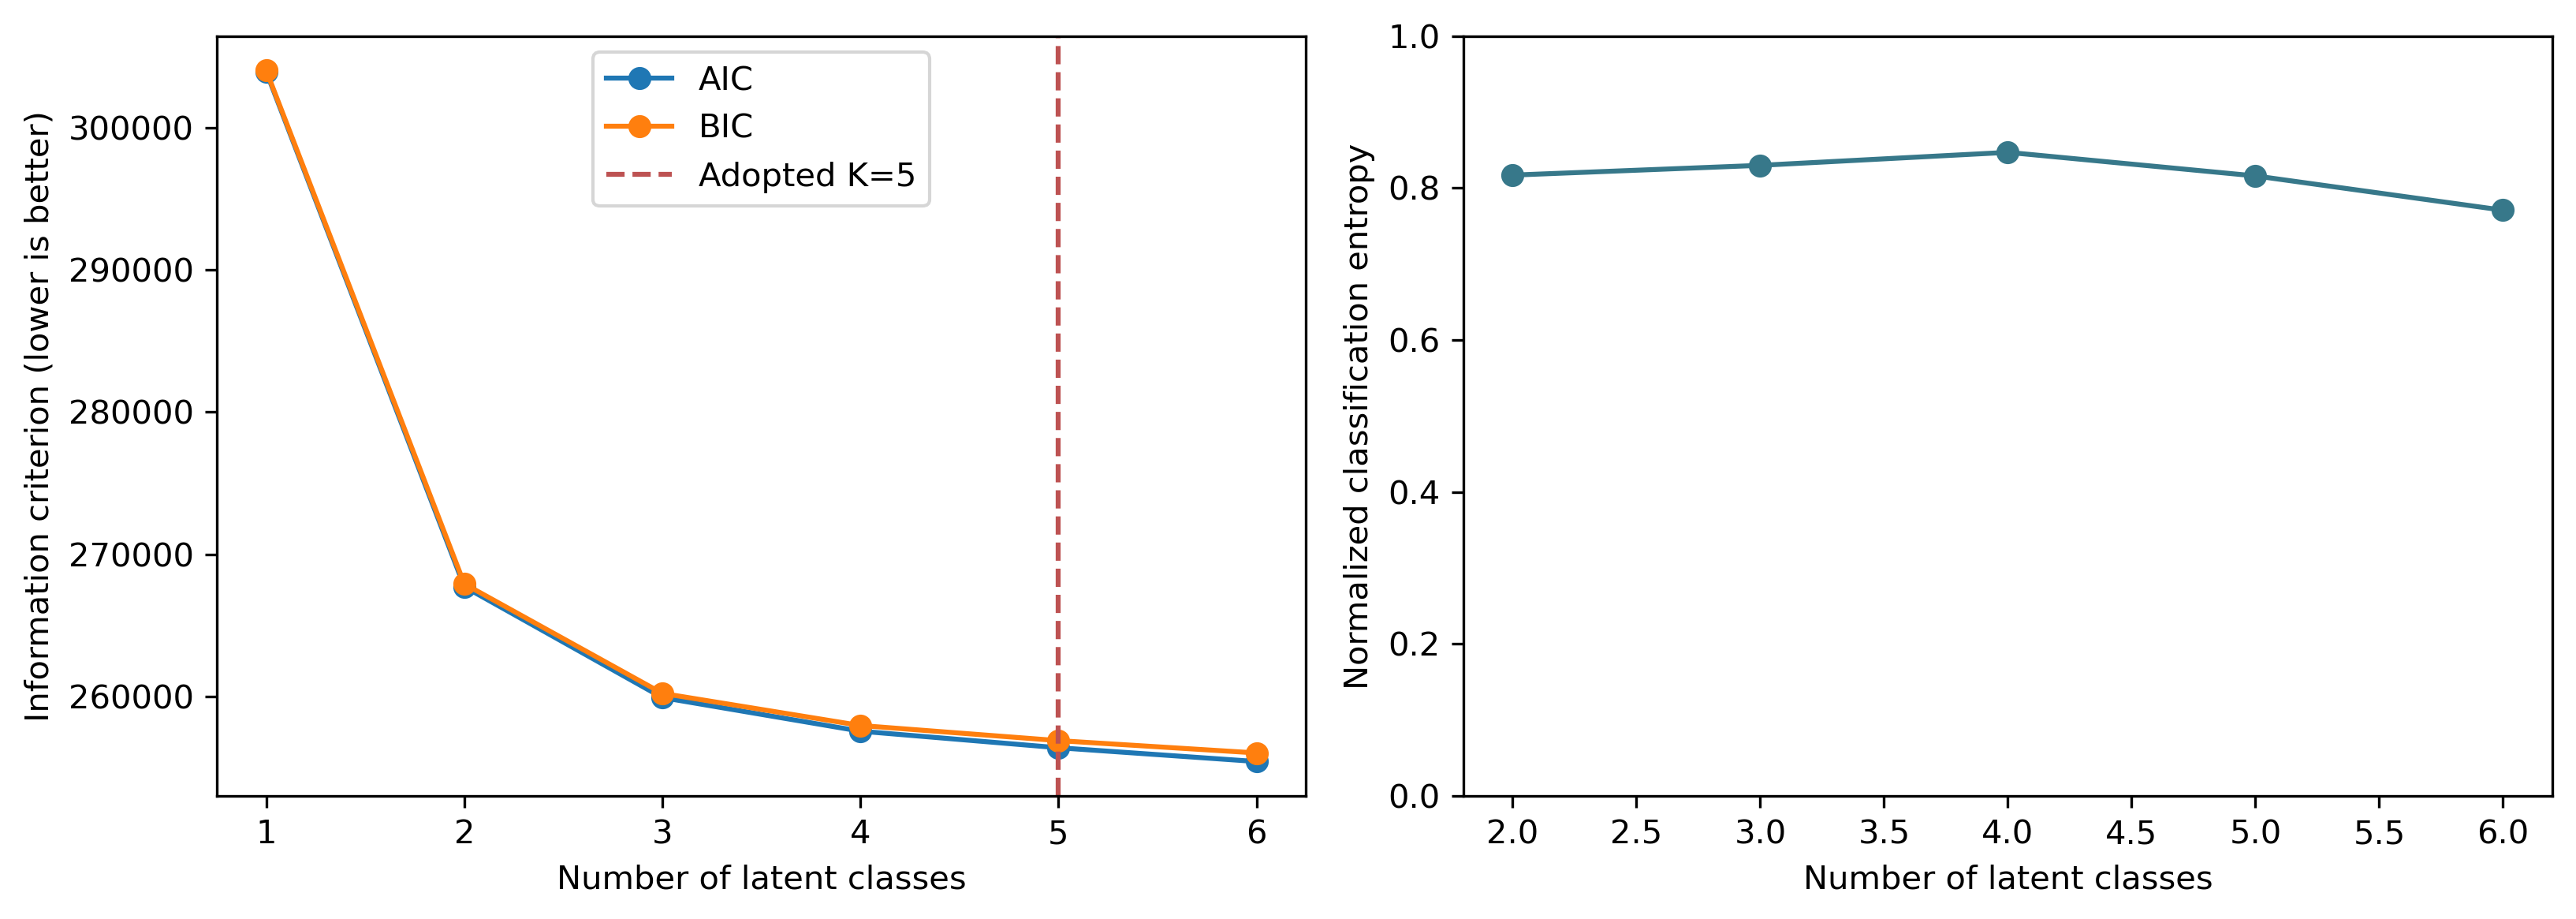

,converged,best_replications,lowest_ll,highest_ll
k,,,,
1,1,1,-151946.787,-151946.787
2,30,30,-133837.554,-133837.554
3,30,30,-129926.326,-129926.326
4,30,21,-129430.285,-128733.944
5,30,17,-128238.982,-128139.732
6,30,28,-127983.834,-127643.734


In [8]:
comparison = pd.read_csv(OUT / 'tables/model_comparison.csv')
display(comparison.round(3))
display(Image(filename=str(OUT / 'figures/LCA1_model_comparison.png')))
starts = pd.read_csv(OUT / 'tables/random_start_diagnostics.csv')
display(starts.groupby('k').agg(converged=('converged', 'sum'), best_replications=('best_replicated', 'sum'), lowest_ll=('log_likelihood','min'), highest_ll=('log_likelihood','max')).round(3))

## 2. 五类条件概率与解释

表中数值为 P(某 ACE=1 | 类别)。沿用已拟合模型按期望 ACE 条目数排序的编号：Class 1 低 ACE 暴露型、Class 2 身体与言语虐待型、Class 3 性虐待主导型、Class 4 家庭功能障碍型、Class 5 多重 ACE 暴露型。

,Class 1,Class 2,Class 3,Class 4,Class 5
ACEDEPRS_bin,0.041,0.267,0.228,0.475,0.640
ACEDRINK_bin,0.087,0.412,0.245,0.727,0.769
ACEDRUGS_bin,0.014,0.012,0.055,0.594,0.423
ACEPRISN_bin,0.010,0.013,0.033,0.302,0.259
ACEDIVRC_bin,0.130,0.331,0.276,0.531,0.642
ACEPUNCH_bin,0.019,0.390,0.115,0.447,0.715
ACEHURT1_bin,0.095,0.574,0.312,0.472,0.815
ACESWEAR_bin,0.101,0.700,0.421,0.637,0.900
ACETOUCH_bin,0.020,0.071,0.940,0.074,0.958
ACETTHEM_bin,0.007,0.019,0.826,0.030,0.855


,class,profile_label,expected_ace_items,leading_items
0,1,低 ACE 暴露型,0.526065,Parental separation/divorce: 0.13; Verbal abus...
1,2,身体与言语虐待型,2.800461,Verbal abuse: 0.70; Physical abuse: 0.57; Hous...
2,3,性虐待主导型,3.856480,Sexual touching: 0.94; Made to touch sexually:...
3,4,家庭功能障碍型,4.297649,Household alcohol problems: 0.73; Verbal abuse...
4,5,多重 ACE 暴露型,7.557164,Sexual touching: 0.96; Verbal abuse: 0.90; Mad...


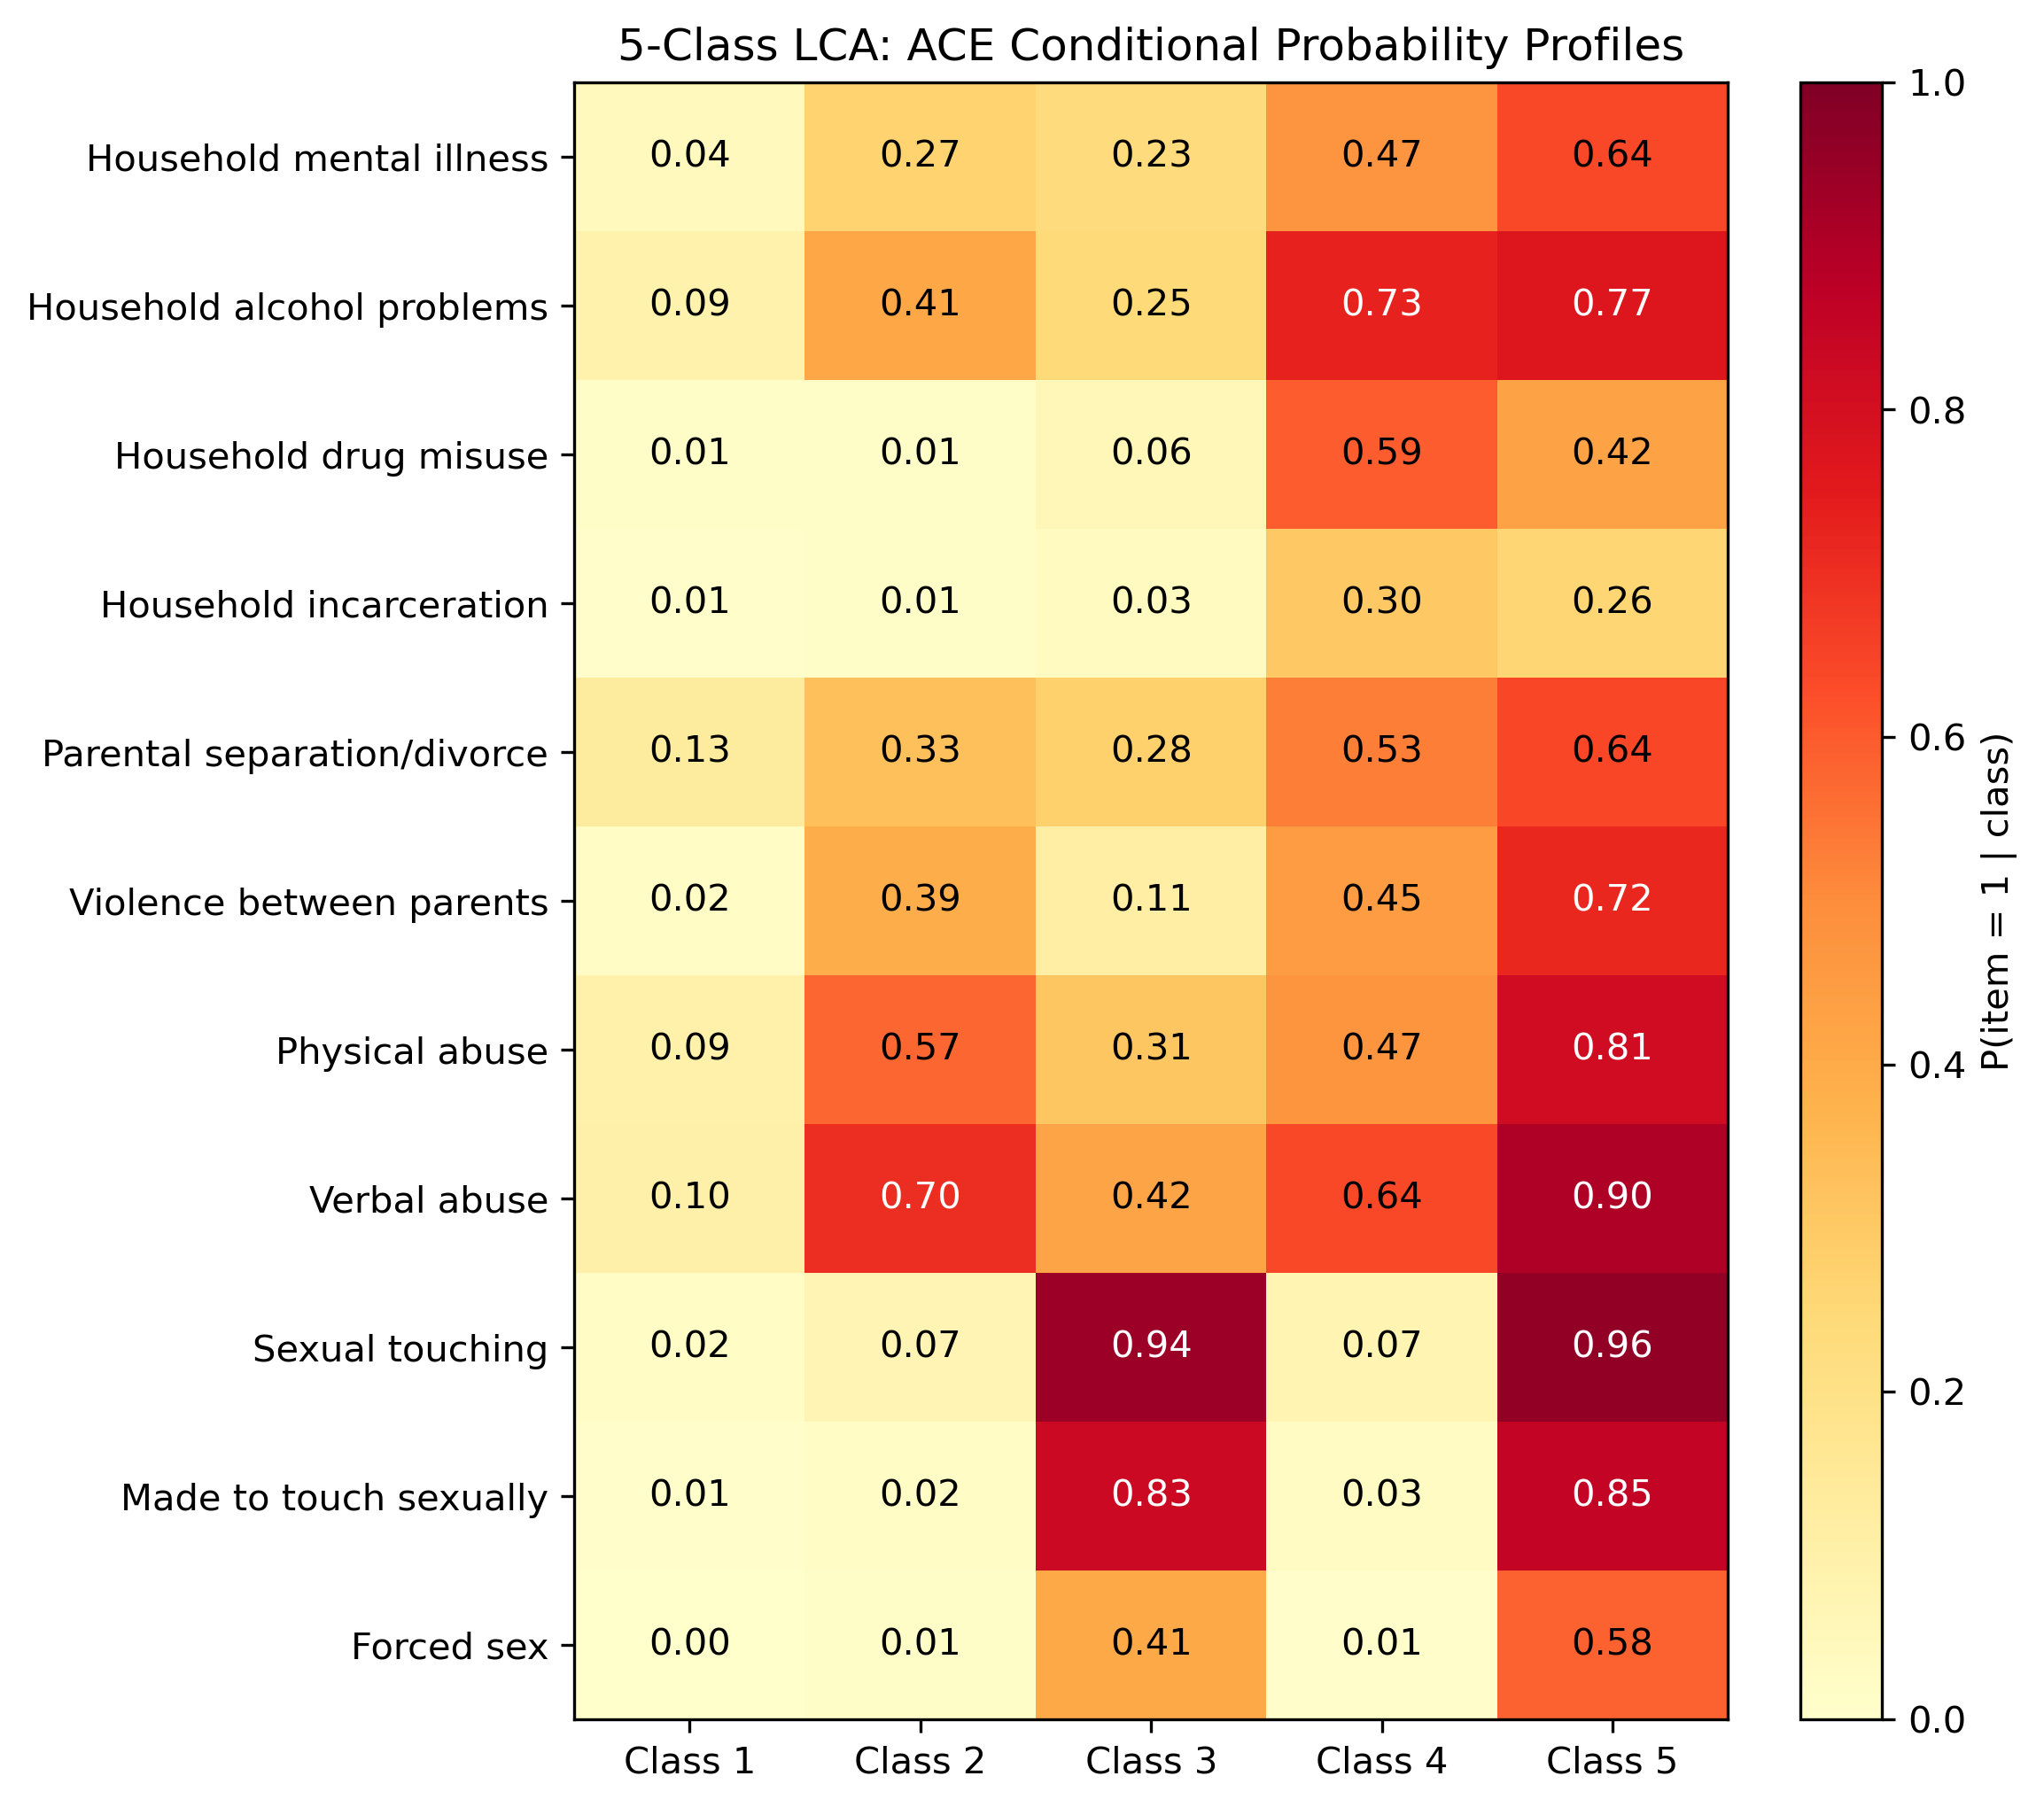

In [9]:
probs = pd.read_csv(OUT / 'tables/selected_item_probabilities.csv', index_col=0)
summary = pd.read_csv(OUT / 'tables/selected_class_summary.csv')
display(probs.round(3))
display(summary[['class','profile_label','expected_ace_items','leading_items']])
display(Image(filename=str(OUT / 'figures/LCA2_class_profiles.png')))

## 3. 类别规模与分类不确定性

模型混合比例、硬分类样本比例和硬分类后的调查加权比例是不同量。保存每人的全部后验概率，最高后验概率低于 0.70 仅作为不确定标志，不删除这些人。

,class,profile_label,model_proportion_pct,modal_n,modal_unweighted_pct,modal_weighted_pct,mean_assigned_posterior,uncertain_lt_0_70_pct
0,1,低 ACE 暴露型,67.578,25095,70.188,69.585,0.928,6.101
1,2,身体与言语虐待型,17.379,6132,17.151,16.884,0.750,44.586
2,3,性虐待主导型,4.413,1407,3.935,3.871,0.895,12.864
3,4,家庭功能障碍型,6.801,1800,5.034,5.527,0.869,15.111
4,5,多重 ACE 暴露型,3.829,1320,3.692,4.133,0.885,15.985


,assigned_class,posterior_class_1,posterior_class_2,posterior_class_3,posterior_class_4,posterior_class_5
0,1,0.928,0.059,0.004,0.009,0.000
1,2,0.129,0.750,0.015,0.098,0.008
2,3,0.008,0.011,0.895,0.003,0.083
3,4,0.038,0.064,0.008,0.869,0.020
4,5,0.000,0.009,0.082,0.025,0.885


数值稳定性：30 个起点收敛，17 个重复达到五类最优对数似然；不等同于 bootstrap 稳定性。


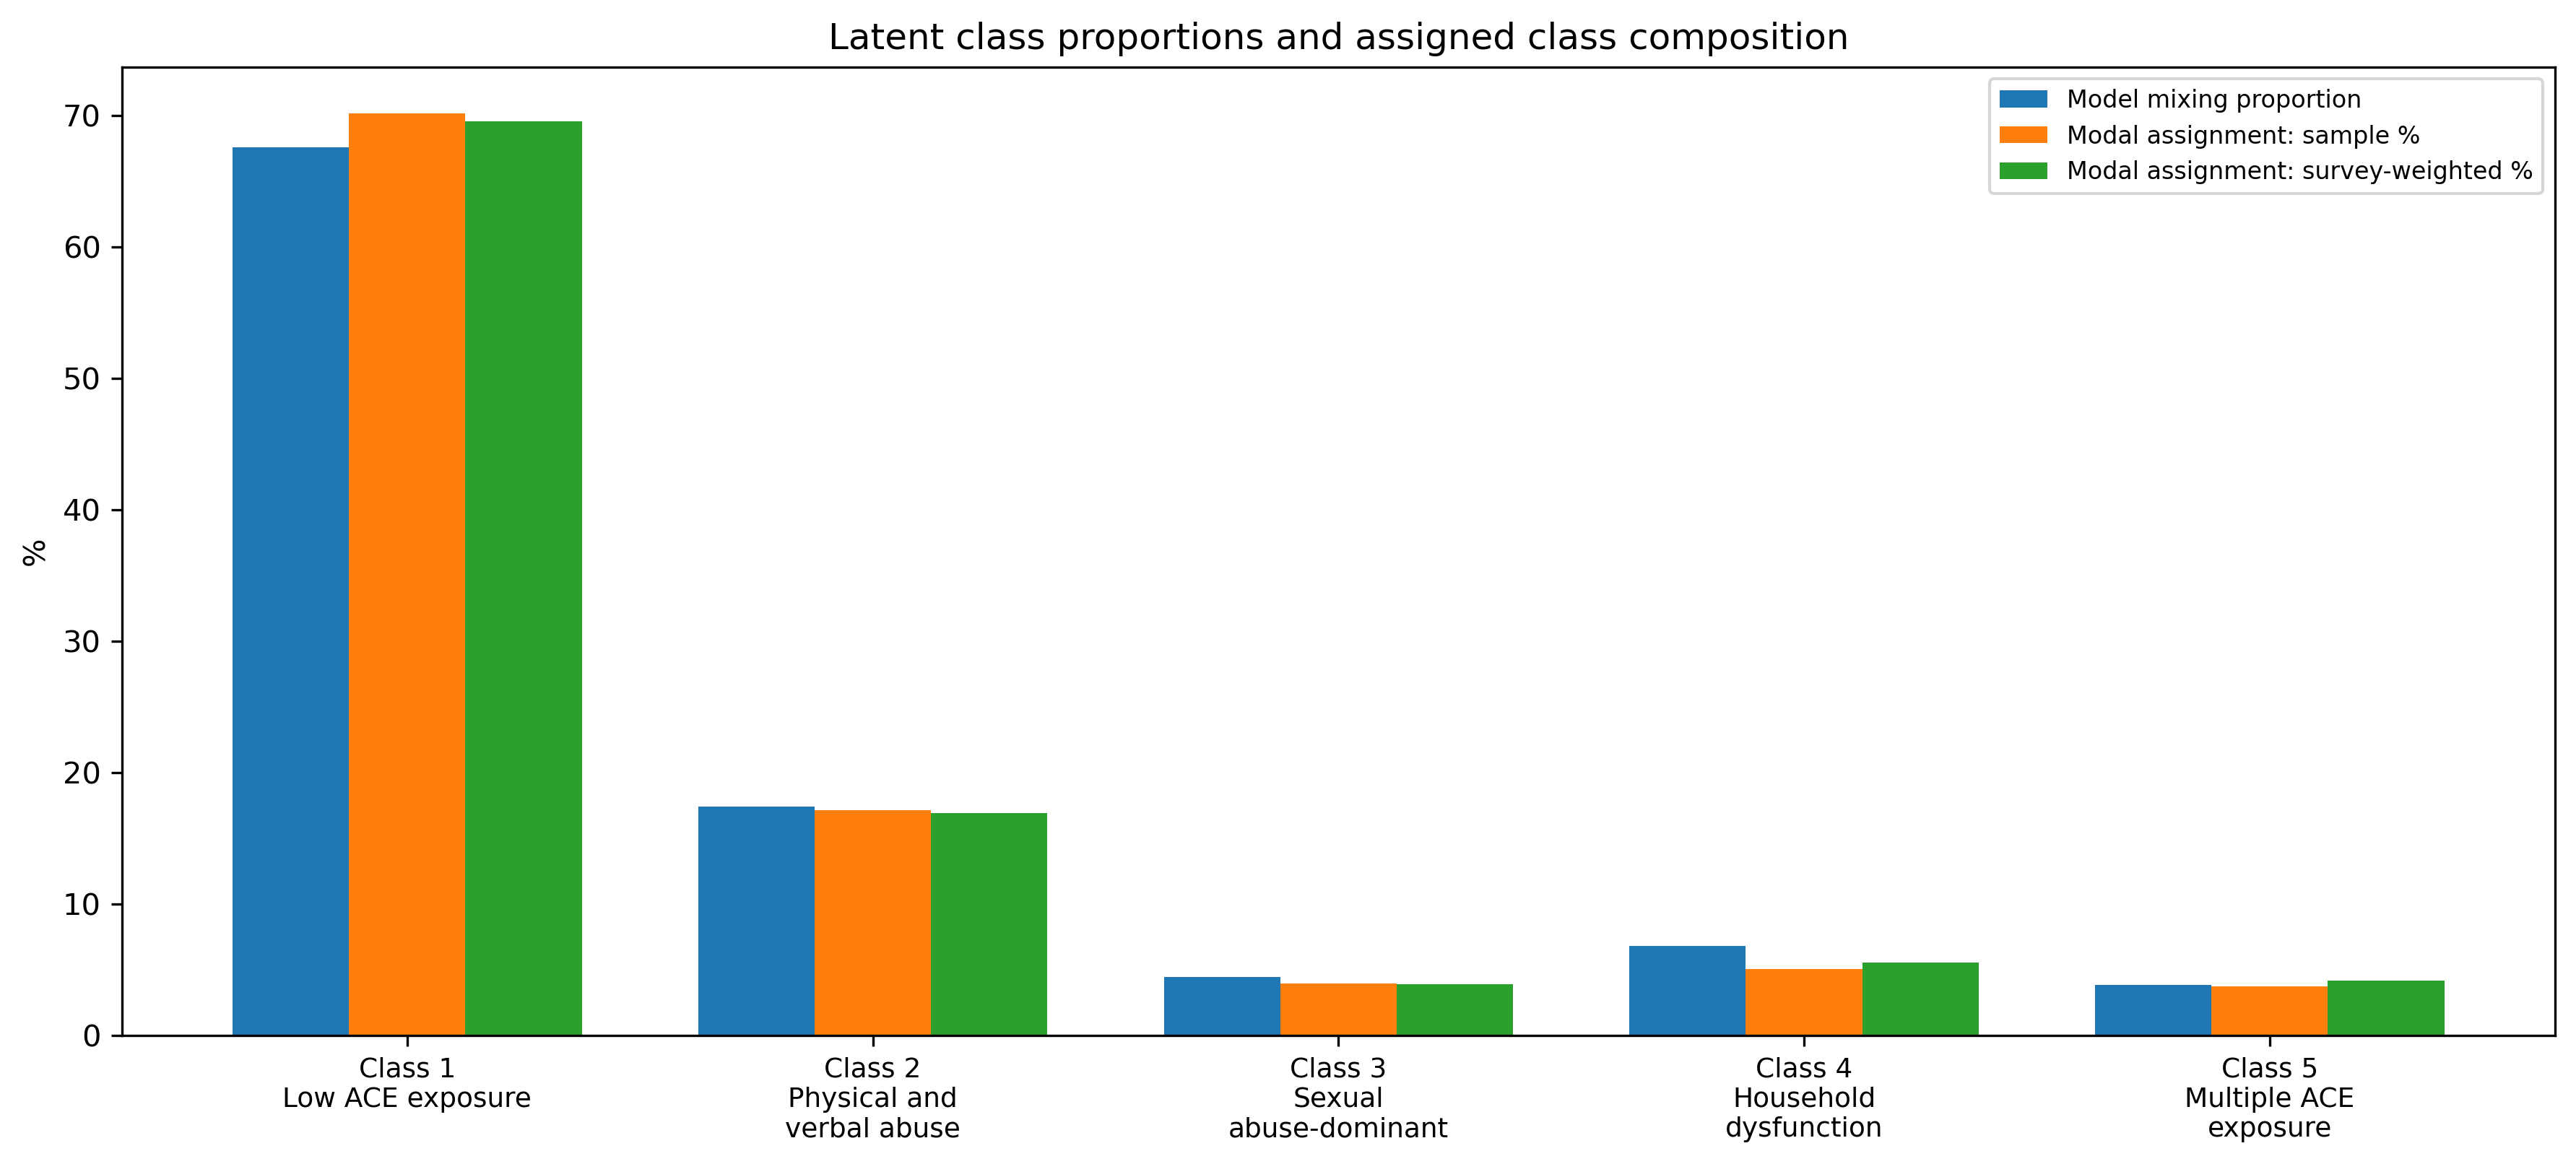

,lca_class,0,1,2-3,4+
0,1,14342,8245,2508,0
1,2,0,0,4164,1968
2,3,0,0,524,883
3,4,0,0,453,1347
4,5,0,0,0,1320


In [10]:
assert audit['selected_k'] == 5
display(summary[['class','profile_label','model_proportion_pct','modal_n','modal_unweighted_pct','modal_weighted_pct','mean_assigned_posterior','uncertain_lt_0_70_pct']].round(3))
display(pd.read_csv(OUT / 'tables/classification_posterior_matrix.csv').round(3))
print('数值稳定性：30 个起点收敛，17 个重复达到五类最优对数似然；不等同于 bootstrap 稳定性。')
display(Image(filename=str(OUT / 'figures/LCA3_class_sizes.png')))
display(pd.read_csv(OUT / 'tables/class_vs_ace_score_group_n.csv'))

## 4. SCD 描述性衔接

图中根据最高后验概率硬分类，百分比使用调查权重。这不是校正分类误差的结局模型。后验加权结果仅为描述性敏感性汇总，不能替代 BCH/三步法等方法；不进行显著性或因果推断。

,class,profile_label,modal_n,SCD_n,SCD_unweighted_pct,SCD_weighted_pct
0,1,低 ACE 暴露型,25095,3415,13.608,13.861
1,2,身体与言语虐待型,6132,1349,21.999,21.510
2,3,性虐待主导型,1407,378,26.866,29.126
3,4,家庭功能障碍型,1800,468,26.000,27.946
4,5,多重 ACE 暴露型,1320,503,38.106,41.391


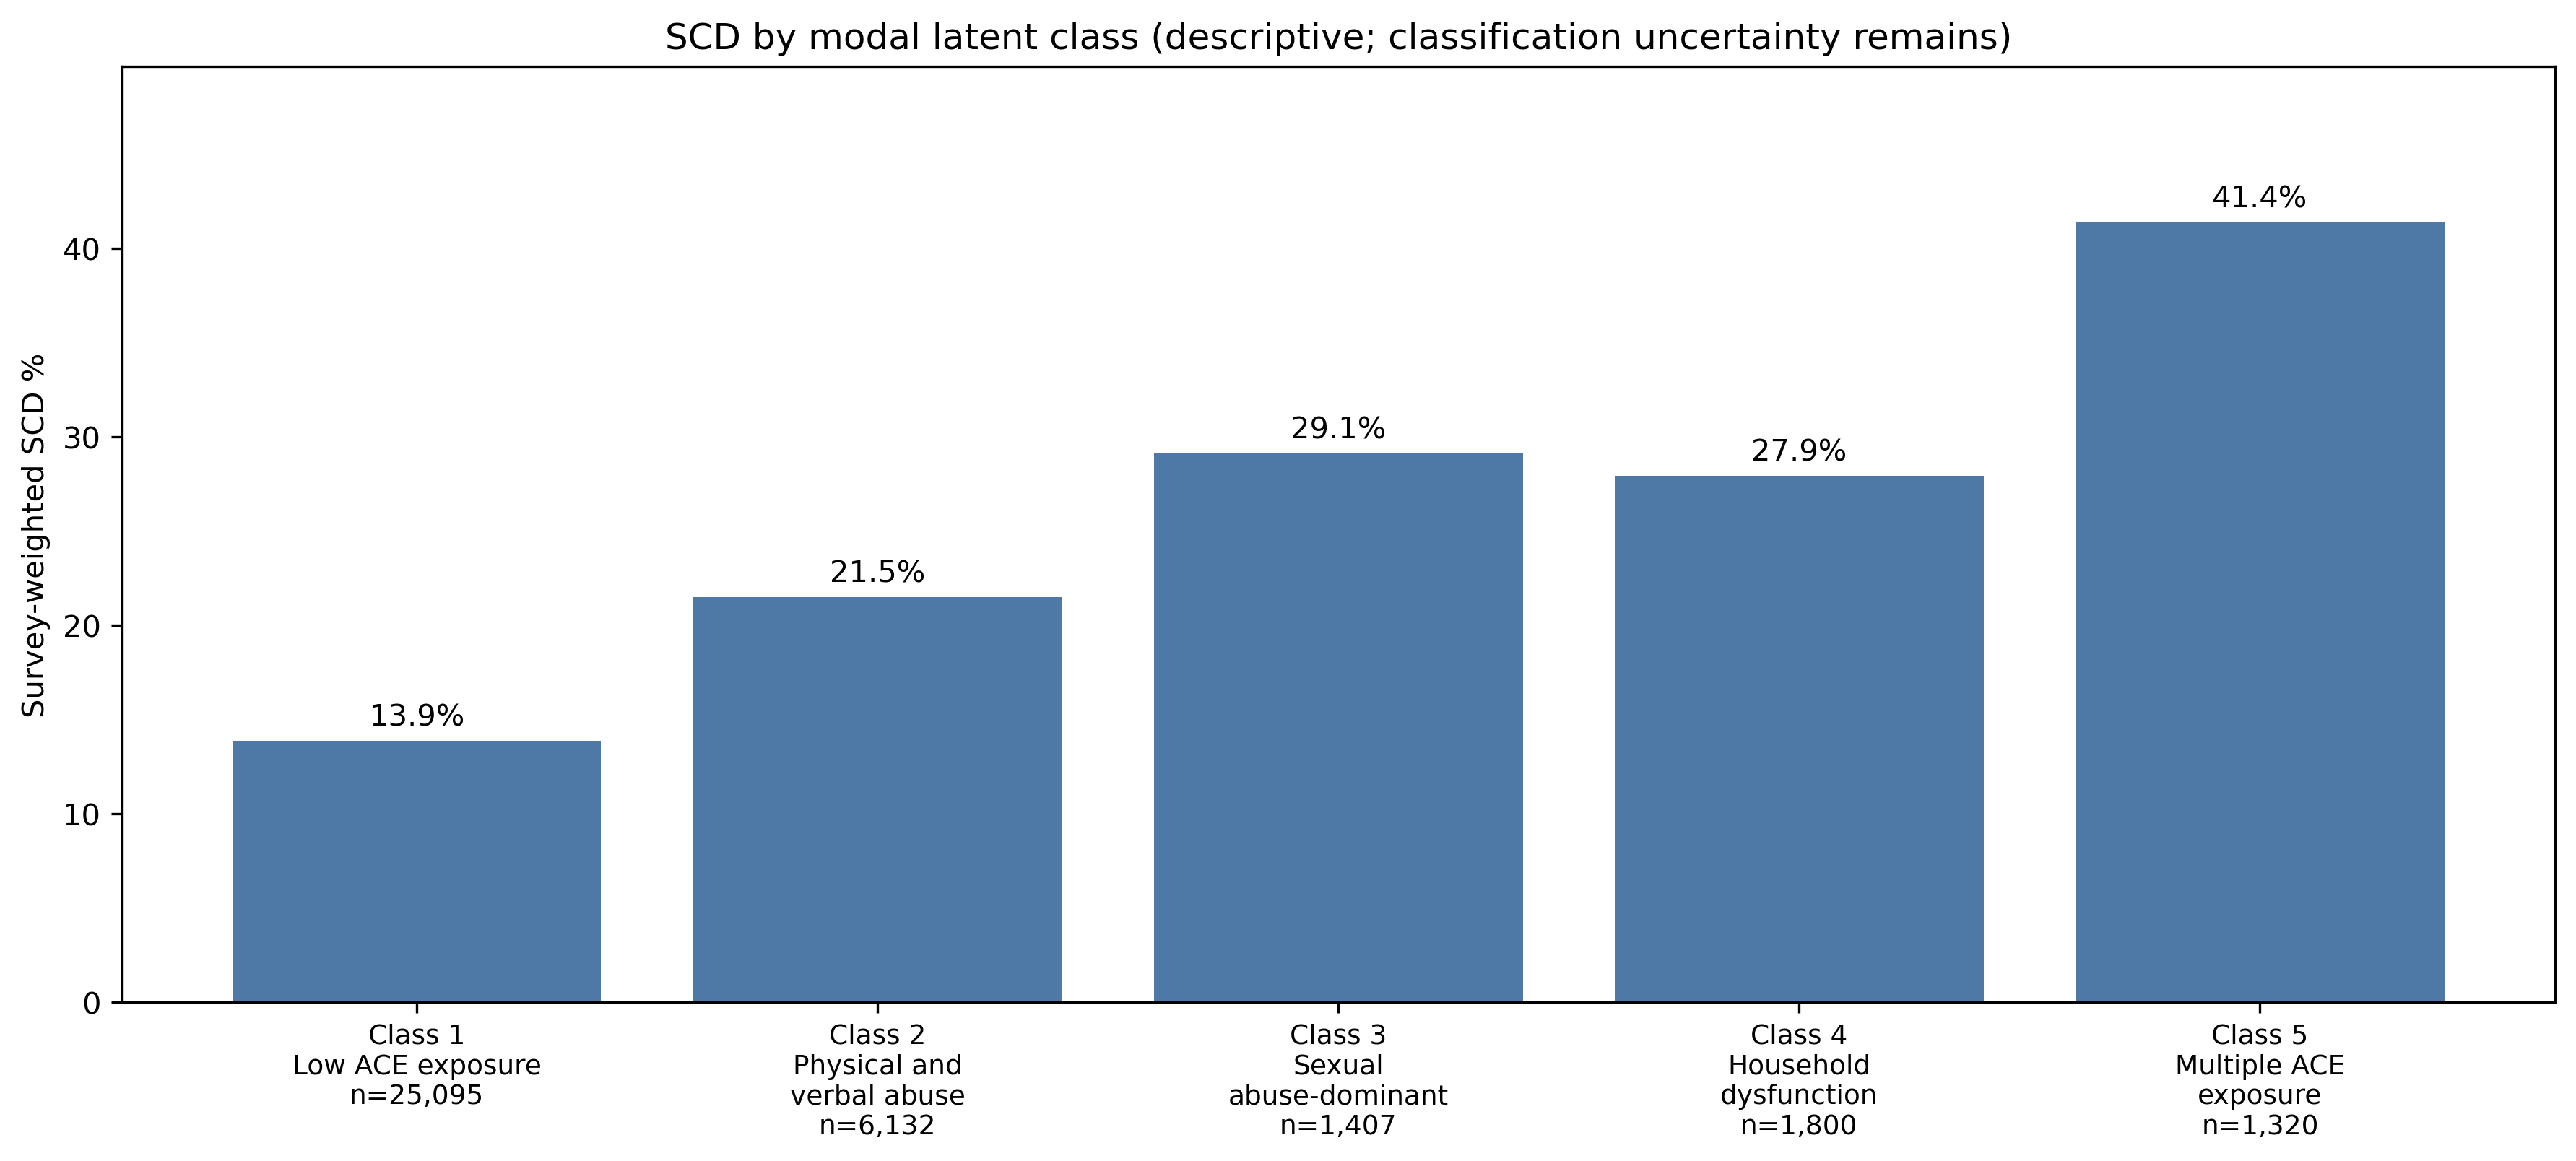

,class,posterior_weighted_SCD_pct,survey_and_posterior_weighted_SCD_pct
0,1,13.568,13.786
1,2,21.073,20.732
2,3,26.635,28.236
3,4,24.461,26.358
4,5,37.272,40.560


In [11]:
display(summary[['class','profile_label','modal_n','SCD_n','SCD_unweighted_pct','SCD_weighted_pct']].round(3))
display(Image(filename=str(OUT / 'figures/LCA4_SCD_by_class.png')))
display(pd.read_csv(OUT / 'tables/SCD_posterior_weighting_descriptive_sensitivity.csv').round(3))

## 5. 局部独立性与数值核验

共现残差是观测比例减去模型预测比例，仅是描述性诊断；三个性虐待条目可能有额外依赖。测试核对解析单类解、聚合似然与逐人似然等价、EM 单调性、保存模型似然、后验概率及样本对齐。

In [12]:
display(pd.read_csv(OUT / 'tables/pairwise_model_residuals.csv').head(10).round(3))
run_checks()

,item_1,item_2,observed_joint_pct,model_joint_pct,residual_percentage_points,absolute_residual_pp
0,ACEHURT1_bin,ACESWEAR_bin,14.463,13.060,1.403,1.403
1,ACEDIVRC_bin,ACEPUNCH_bin,6.852,5.919,0.934,0.934
2,ACEDRINK_bin,ACEPUNCH_bin,8.164,7.336,0.828,0.828
3,ACEPUNCH_bin,ACEHURT1_bin,8.645,7.830,0.815,0.815
4,ACEDEPRS_bin,ACESWEAR_bin,8.925,8.209,0.716,0.716
5,ACEDRINK_bin,ACEHURT1_bin,9.090,9.736,-0.646,0.646
6,ACEDRINK_bin,ACEDIVRC_bin,8.547,7.950,0.597,0.597
7,ACEDRUGS_bin,ACEPRISN_bin,2.064,1.660,0.404,0.404
8,ACEDEPRS_bin,ACEDRUGS_bin,3.468,3.103,0.365,0.365
9,ACEDEPRS_bin,ACEDRINK_bin,6.973,6.628,0.345,0.345


PASS: analytic K=1, mixture fixture, compressed likelihood, all saved LLs, monotone EM, posterior/mixing sums, assignments, row alignment and SCD totals.


## 6. 五个 LCA 类别的人口统计特征

比较各类内部性别、教育、收入、年龄、婚姻及种族/族裔构成。按最高后验概率硬分类；百分比使用调查权重，以每个类别为分母，缺失单列。只作描述性比较。

PASS: class membership, demographic denominators and weighted 100% sums.


,variable,level,1,2,3,4,5
0,sex,Male,"11,307 (47.0%)","2,740 (46.9%)",376 (28.3%),903 (54.9%),301 (29.2%)
1,sex,Female,"13,788 (53.0%)","3,392 (53.1%)","1,031 (71.7%)",897 (45.1%),"1,019 (70.8%)"
2,sex,Missing,0 (0.0%),0 (0.0%),0 (0.0%),0 (0.0%),0 (0.0%)
3,education,High school or less,"7,155 (34.0%)","1,661 (33.6%)",383 (33.2%),610 (42.5%),439 (43.6%)
4,education,Attended college,"6,299 (30.1%)","1,579 (31.6%)",438 (35.5%),535 (32.0%),461 (35.1%)
5,education,College graduate,"11,573 (35.5%)","2,871 (34.5%)",585 (31.4%),652 (25.4%),417 (21.2%)
6,education,Missing,68 (0.3%),21 (0.3%),1 (0.0%),3 (0.2%),3 (0.1%)
7,income,<$15k,851 (3.9%),272 (4.3%),95 (6.3%),124 (5.9%),135 (8.7%)
8,income,$15-25k,"1,844 (7.6%)",451 (7.8%),151 (10.5%),173 (7.9%),176 (11.8%)
9,income,$25-35k,"2,217 (8.4%)",599 (8.5%),143 (9.2%),177 (9.8%),151 (12.3%)


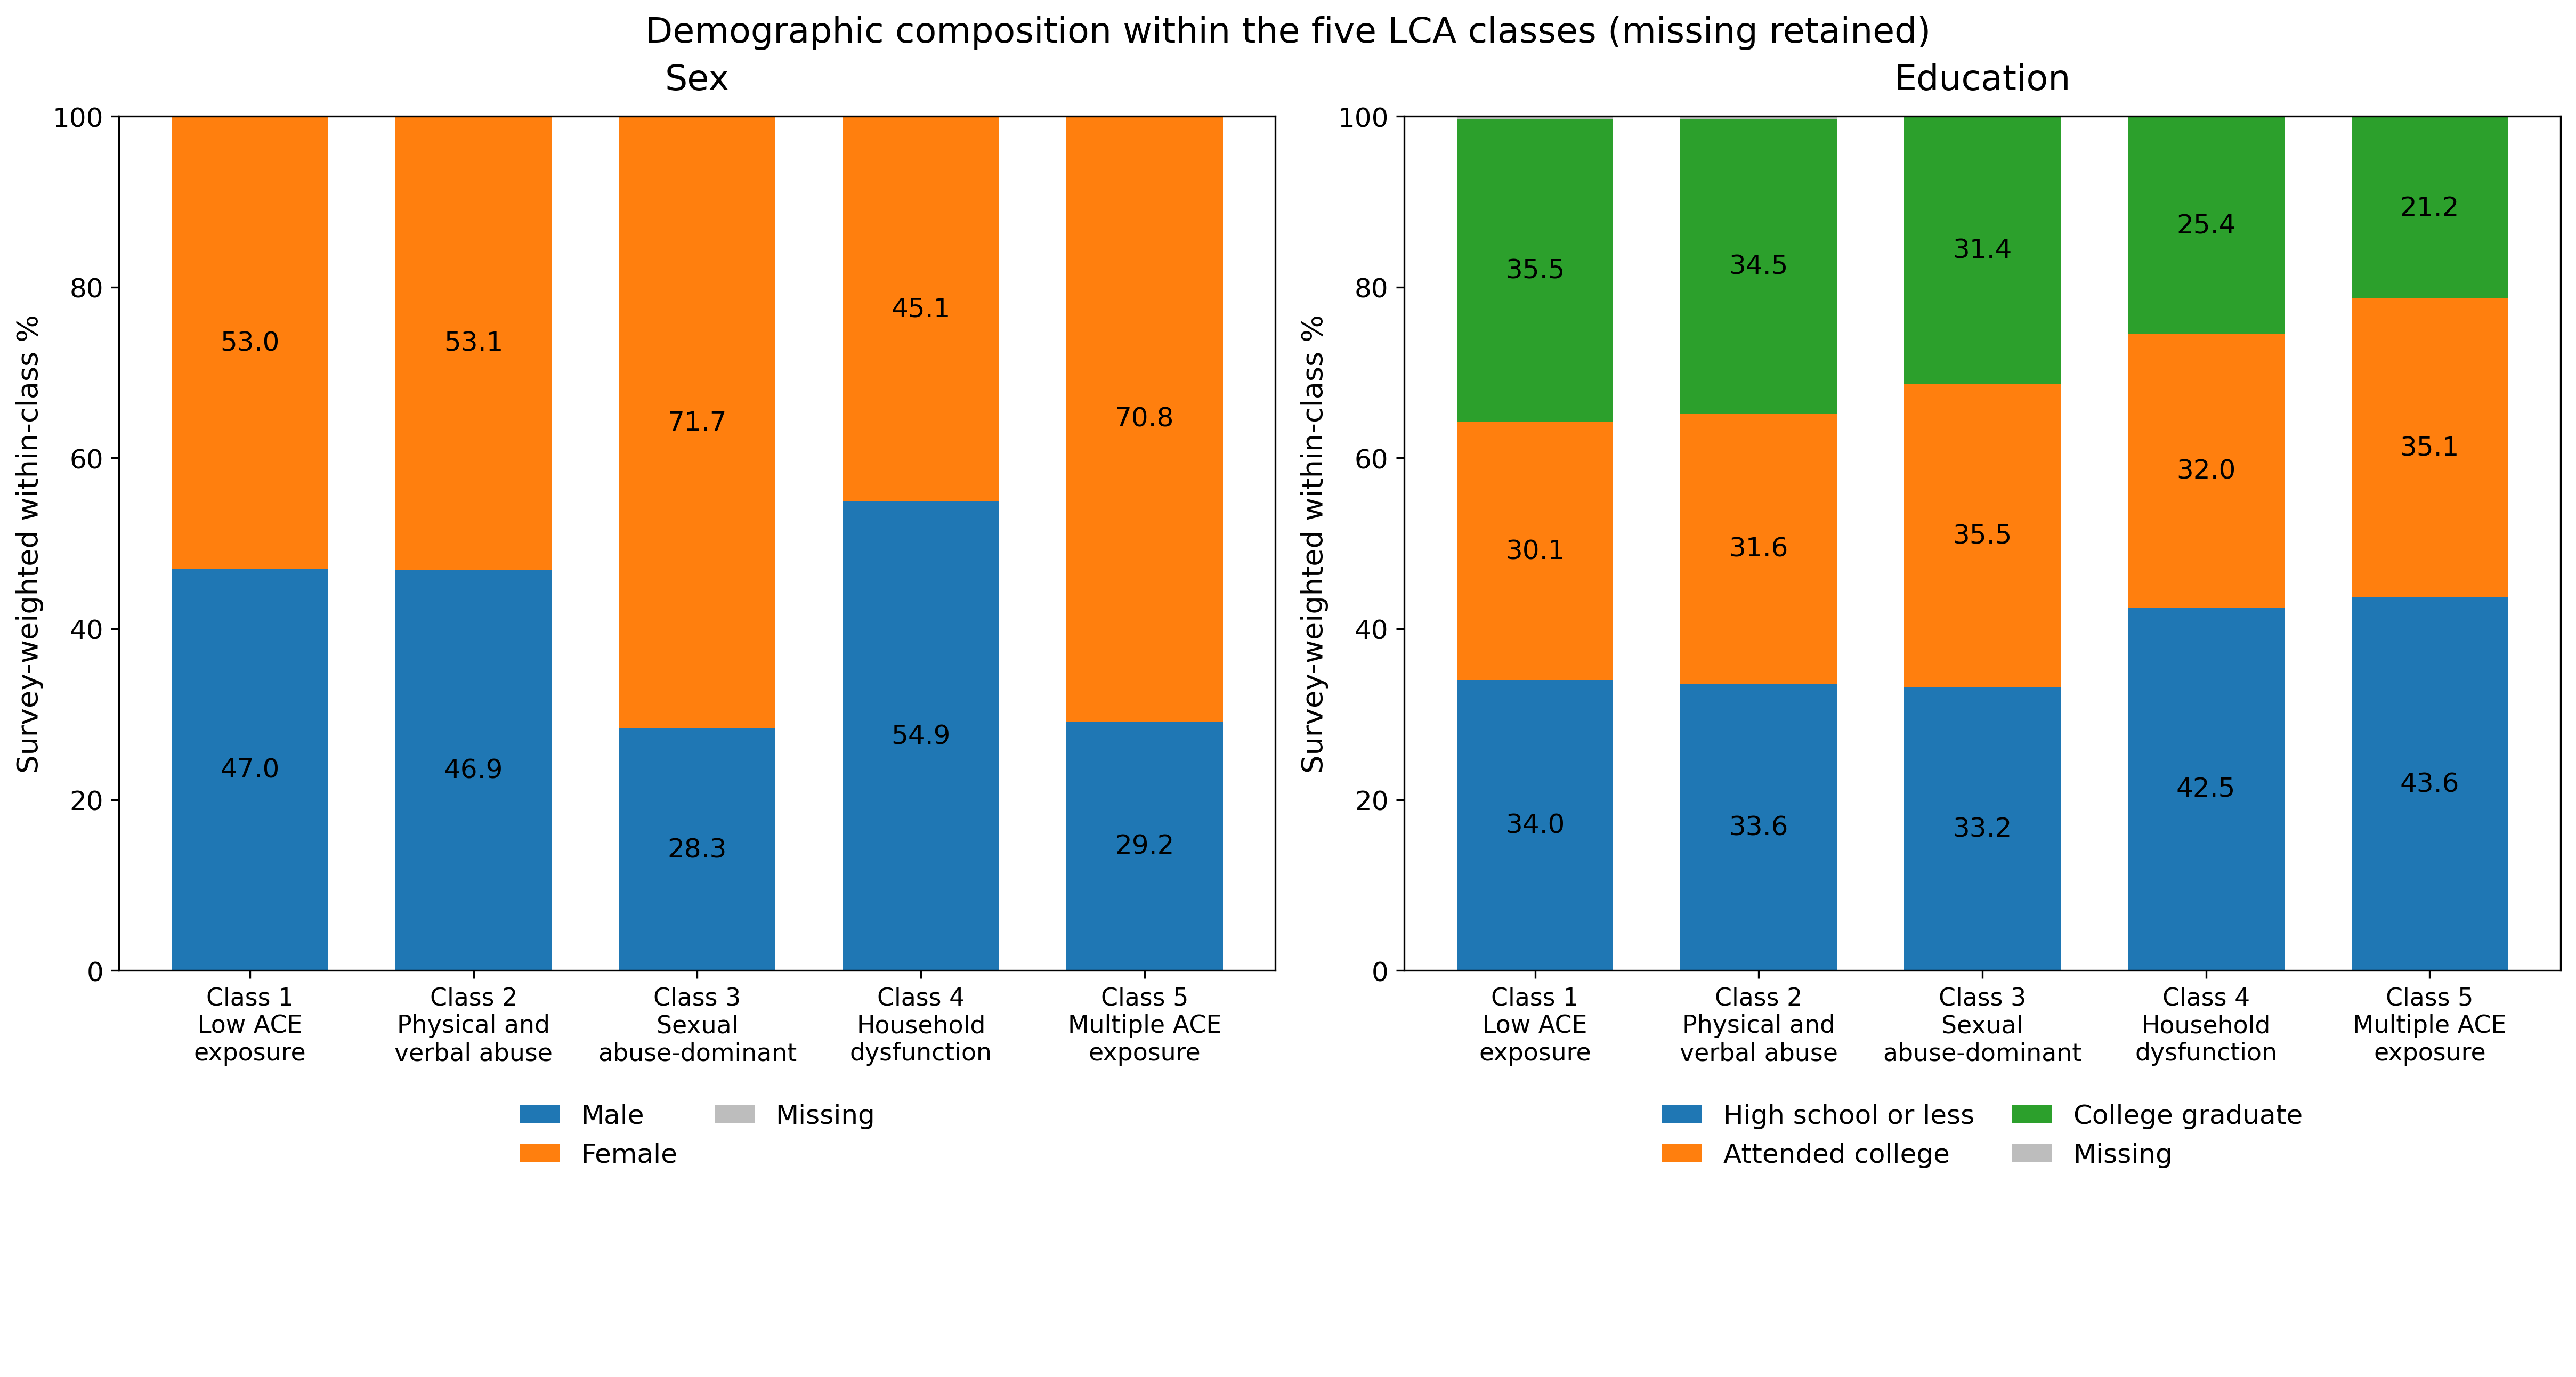

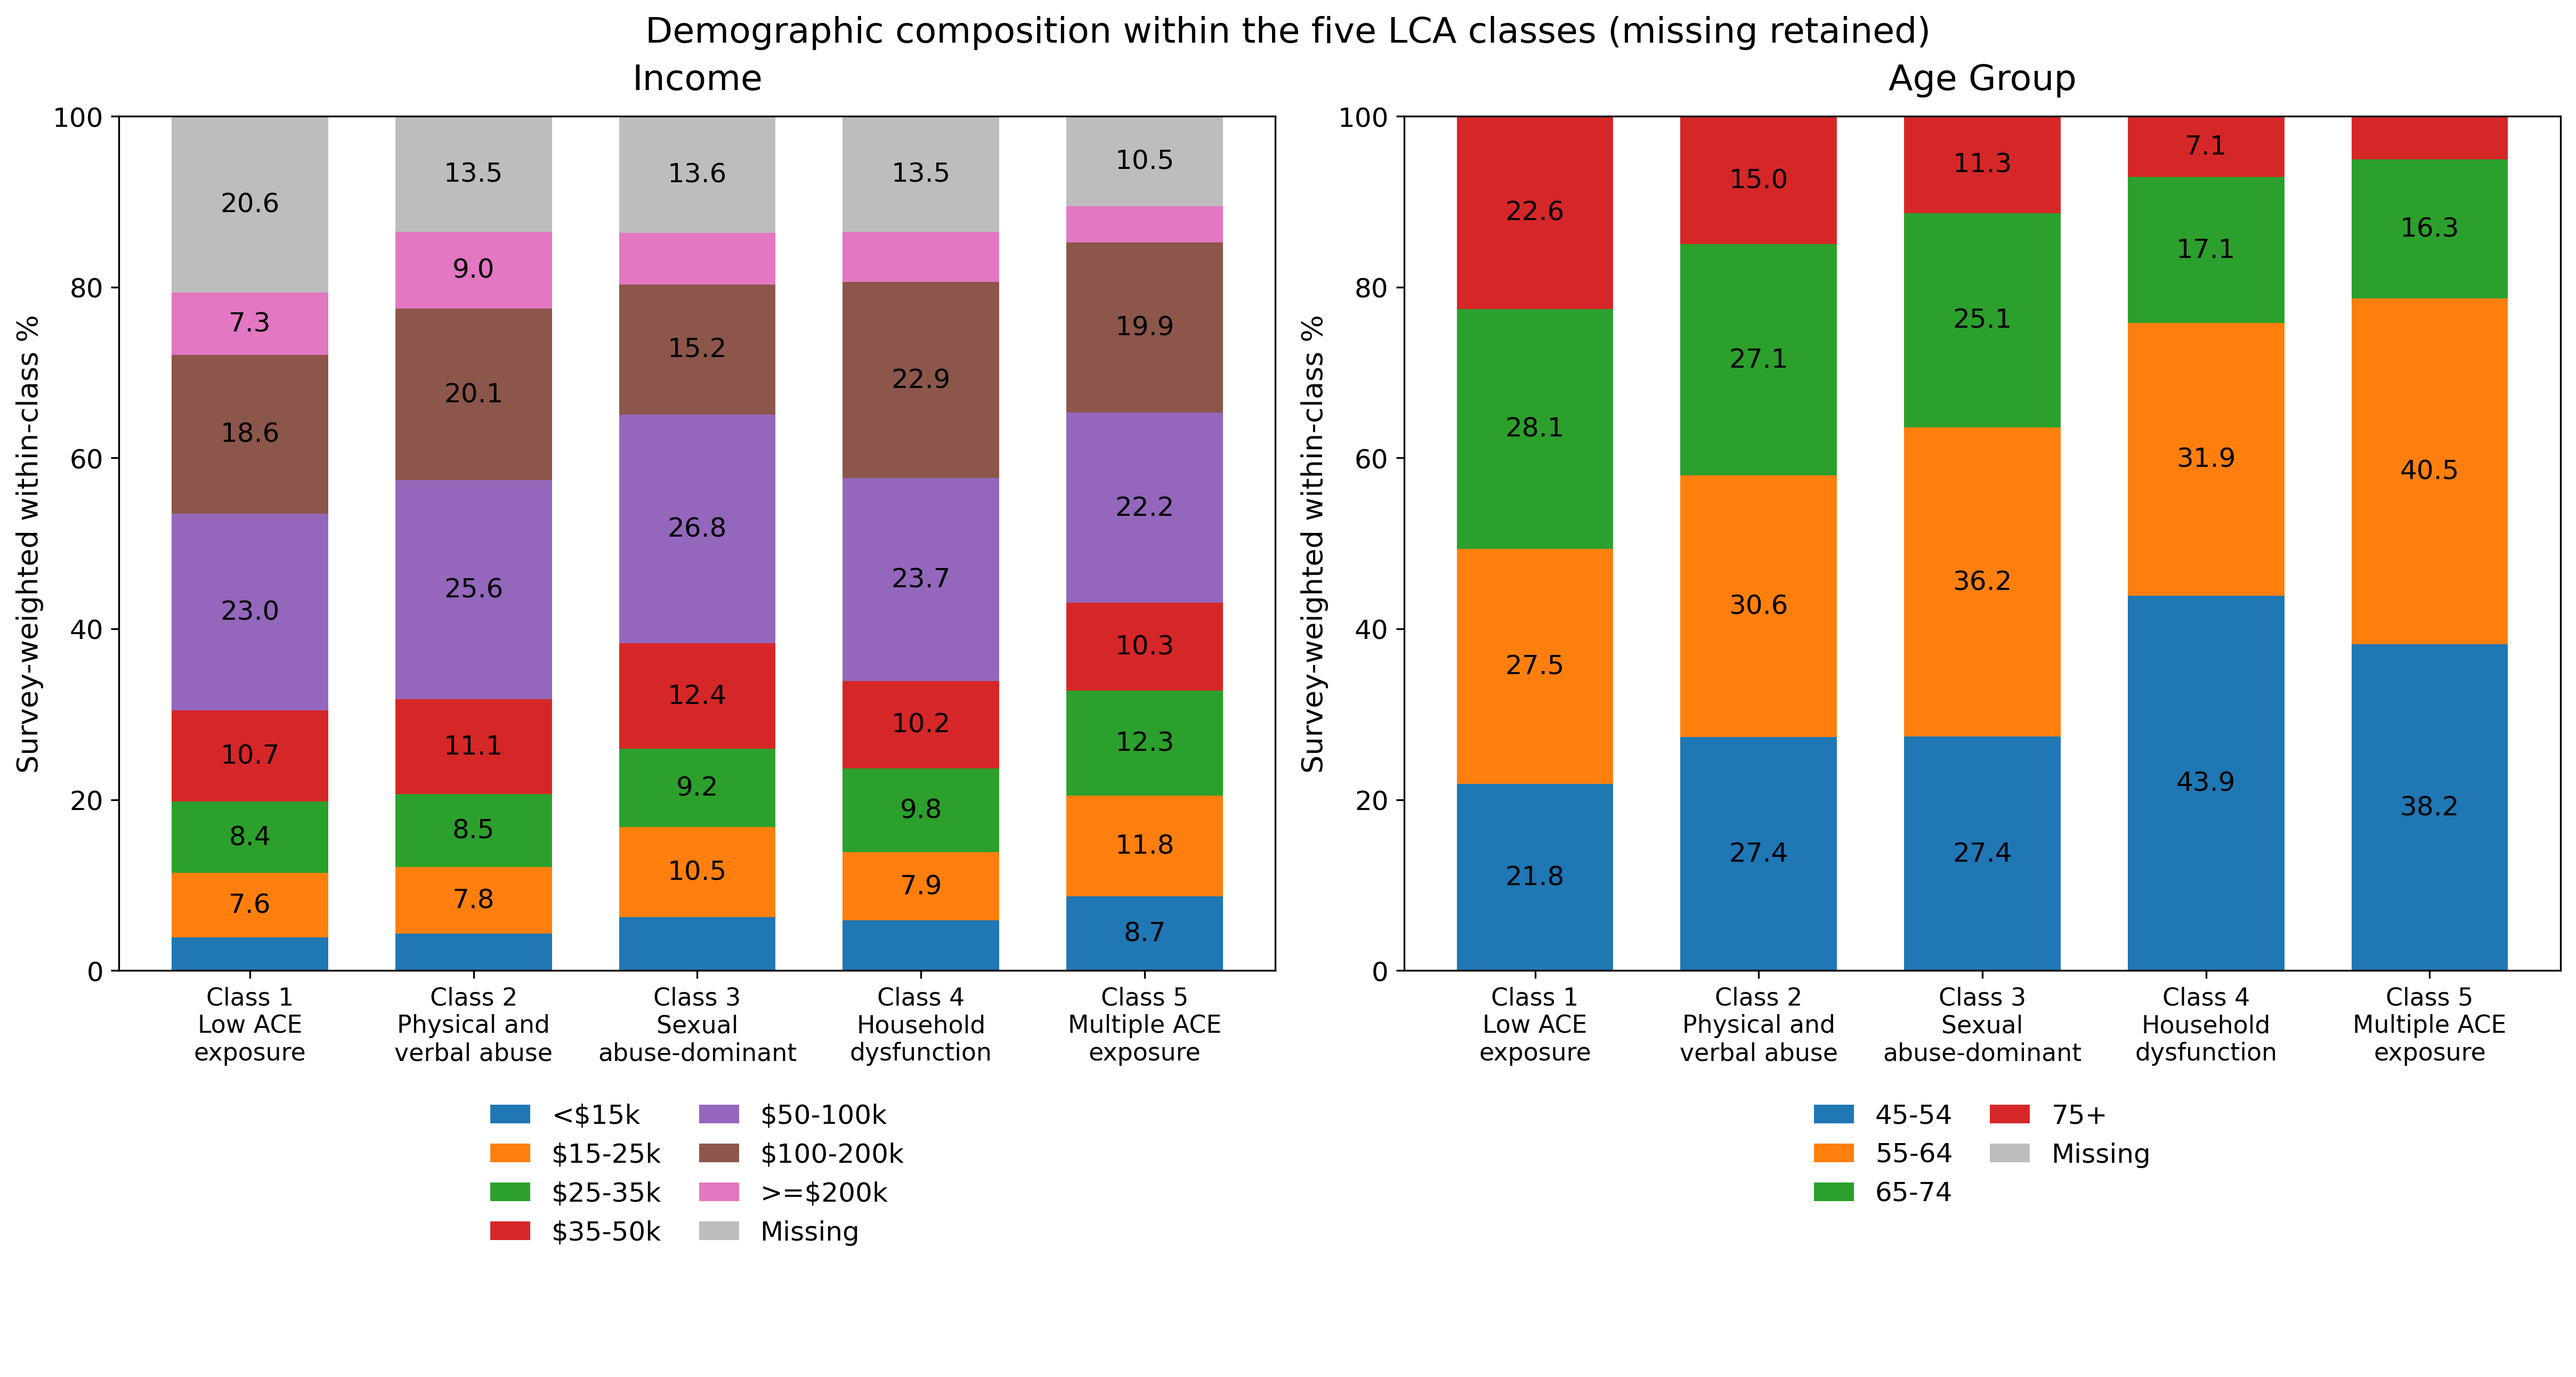

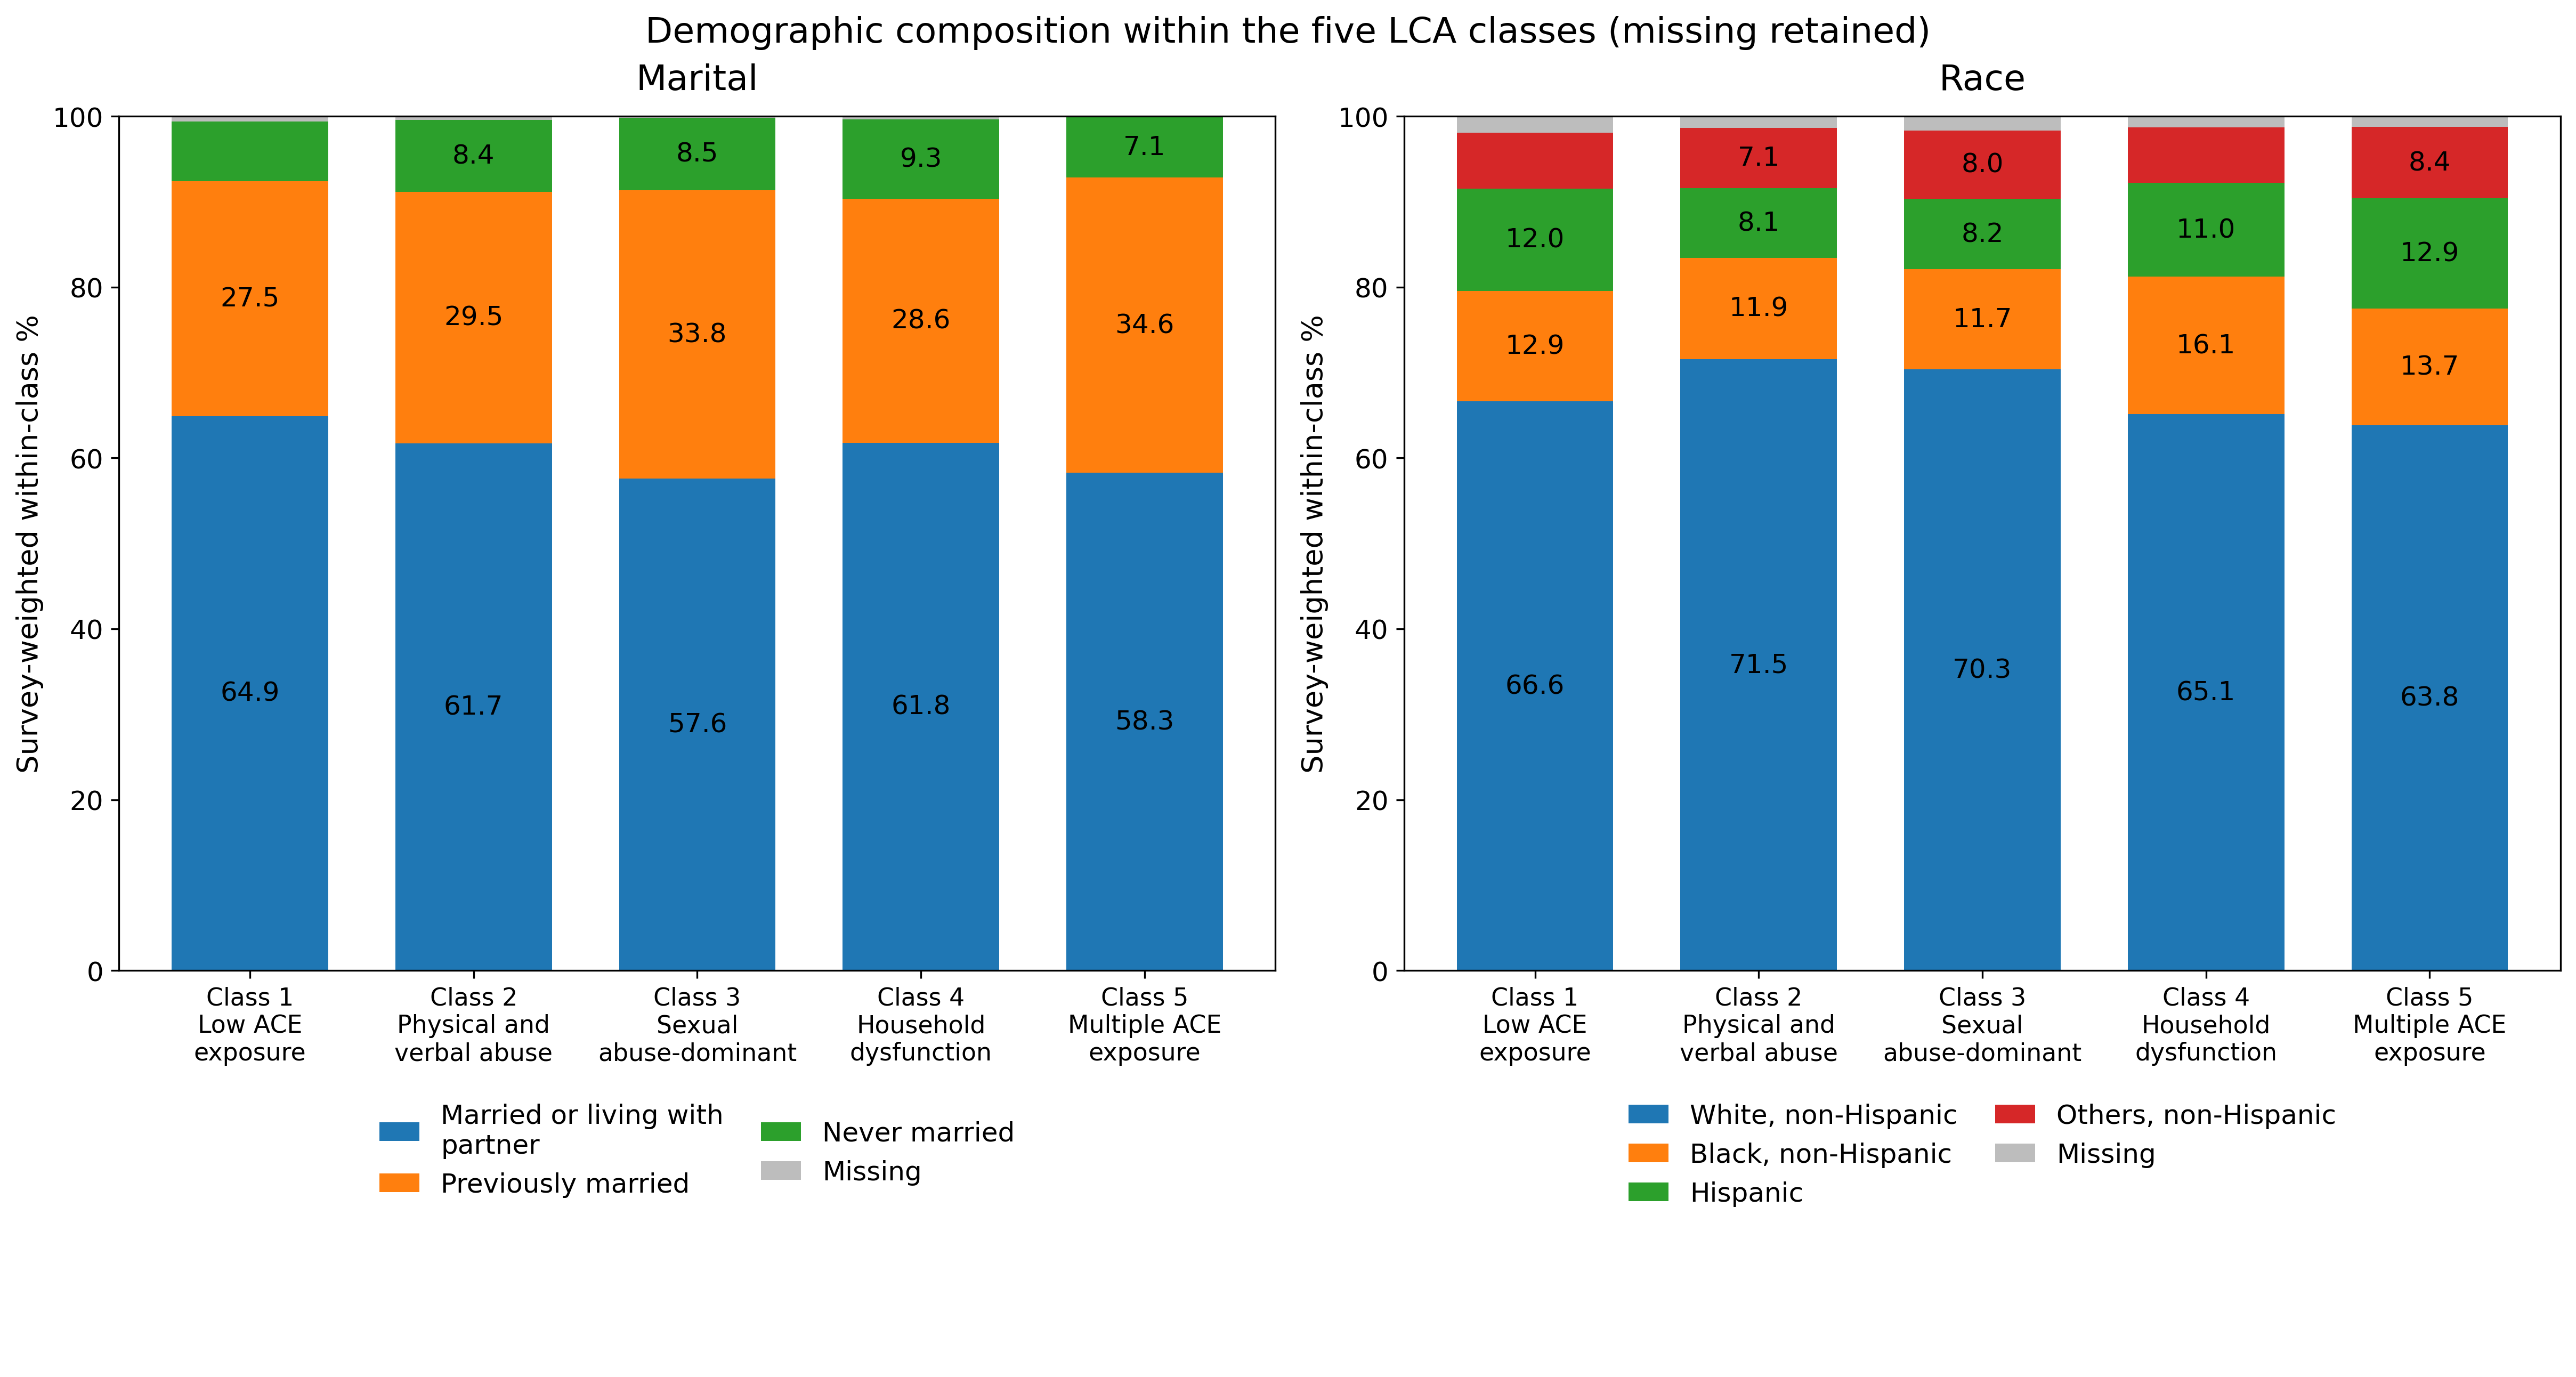

In [13]:
group_results = run_group_analysis()

display(pd.read_csv(OUT / 'tables/demographics_by_lca_class_n_weighted_pct.csv').fillna(''))

display(Image(filename=str(OUT / 'figures/LCA5_demographics_sex_education.png')))

display(Image(filename=str(OUT / 'figures/LCA6_demographics_income_age_group.png')))

display(Image(filename=str(OUT / 'figures/LCA7_demographics_marital_race.png')))


## 4、5、6 类条件概率热力图对照导出

从本 Notebook 保存的模型参数生成统一 0–1 色标的比较热力图及概率表，无需外部脚本。

In [16]:
"""Export comparable K=4, K=5 and K=6 profiles from saved fitted models."""
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def export_profile_comparisons(class_counts=(4, 5, 6)):
    for k in class_counts:
        with np.load(OUT / 'models' / f'lca_k{k}.npz') as model:
            assert model['columns'].tolist() == COLS
            theta = model['theta'].copy()
            pi = model['pi'].copy()
        assert theta.shape == (k, 11)
        assert np.isfinite(theta).all() and ((theta >= 0) & (theta <= 1)).all()
        pd.DataFrame(theta.T, index=COLS, columns=[f'Class {c + 1}' for c in range(k)]).to_csv(OUT / 'tables' / f'item_probabilities_k{k}.csv', encoding='utf-8-sig')
        fig, ax = plt.subplots(figsize=(12 if k == 5 else max(8, k * 1.3), 9 if k == 5 else 8))
        im = ax.imshow(theta.T, cmap='YlOrRd', vmin=0, vmax=1, aspect='auto')
        tick_labels = [class_plot_label(c + 1, f'({pi[c] * 100:.1f}%)') if k == 5
                       else f'Class {c + 1}\n({pi[c] * 100:.1f}%)' for c in range(k)]
        ax.set_xticks(range(k), tick_labels, fontsize=9)
        ax.set_yticks(range(11), LABELS.values())
        for i in range(11):
            for c in range(k):
                value = theta[c, i]
                ax.text(c, i, f'{value:.2f}', ha='center', va='center', color='white' if value > 0.65 else 'black')
        ax.set_title(f'{k}-Class LCA: ACE Conditional Probability Profiles\nClasses ordered by expected ACE item count; percentages = model mixing proportions', fontsize=12)
        fig.colorbar(im, ax=ax, label='P(ACE item = 1 | latent class)')
        for ext in ['png', 'pdf']:
            path = OUT / 'figures' / f'LCA_class_profiles_k{k}.{ext}'
            fig.savefig(path, dpi=300, bbox_inches='tight')
            print(path)
        plt.close(fig)

export_profile_comparisons()

D:\CityU\DSC5002\Project\ACE_classification_gao\lca\figures\LCA_class_profiles_k4.png
D:\CityU\DSC5002\Project\ACE_classification_gao\lca\figures\LCA_class_profiles_k4.pdf
D:\CityU\DSC5002\Project\ACE_classification_gao\lca\figures\LCA_class_profiles_k5.png
D:\CityU\DSC5002\Project\ACE_classification_gao\lca\figures\LCA_class_profiles_k5.pdf
D:\CityU\DSC5002\Project\ACE_classification_gao\lca\figures\LCA_class_profiles_k6.png
D:\CityU\DSC5002\Project\ACE_classification_gao\lca\figures\LCA_class_profiles_k6.pdf
